# Cross-session validation of contrast-dependent population dynamics in MOs

## Question

Are the contrast-dependent population dynamics observed in the prototype
MOs session reproducible across independent recording sessions?

## Main measurements

1. Stimulus-side population separation
2. Population trajectory excursion
3. Contrast dependence of these metrics
4. Across-session reproducibility

## steps
1. global inventory
2. MOs sessions
3. cross session：
    load NWB
    unit/trial QC
    stimulus-aligned binning
    smoothing
    soft normalization
    condition-average trajectories
    compute：
    trajectory excursion
    left-right separation
    peak / mean / AUC
4. summary
5. close NWB

In [1]:
# ============================================================
# 00. Imports
# ============================================================

from pathlib import Path
import gc
import traceback

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


pd.set_option(
    "display.max_columns",
    None,
)

pd.set_option(
    "display.max_rows",
    100,
)

In [2]:
# ============================================================
# 01. Project paths
# ============================================================

PROJECT_DIR = Path(
    r"D:\Ephys_analysis\ibl-population-dynamics"
)

GLOBAL_DIR = (
    PROJECT_DIR
    / "results"
    / "global_inventory"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "cross_session_MOs"
)

TABLE_DIR = (
    OUTPUT_DIR
    / "tables"
)

SESSION_RESULT_DIR = (
    OUTPUT_DIR
    / "session_results"
)

SUMMARY_FIGURE_DIR = (
    OUTPUT_DIR
    / "summary_figures"
)


# Create output folders
for folder in [
    OUTPUT_DIR,
    TABLE_DIR,
    SESSION_RESULT_DIR,
    SUMMARY_FIGURE_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "Project directory:",
    PROJECT_DIR,
)

print(
    "Global inventory:",
    GLOBAL_DIR,
)

print(
    "Cross-session output:",
    OUTPUT_DIR,
)

Project directory: D:\Ephys_analysis\ibl-population-dynamics
Global inventory: D:\Ephys_analysis\ibl-population-dynamics\results\global_inventory
Cross-session output: D:\Ephys_analysis\ibl-population-dynamics\results\cross_session_MOs


In [3]:
# ============================================================
# 02. Analysis configuration
# ============================================================

TARGET_REGION = (
    "Secondary motor area"
)

REGION_SHORT_NAME = (
    "MOs"
)


# ------------------------------------------------------------
# Visual contrasts included in the main analysis
# ------------------------------------------------------------

ANALYSIS_CONTRASTS = [
    6.25,
    12.5,
    25.0,
    100.0,
]

ANALYSIS_SIDES = [
    "left",
    "right",
]


# ------------------------------------------------------------
# Session eligibility criteria
#
# These are initial pragmatic thresholds.
# We will inspect the inventory before finalizing them.
# ------------------------------------------------------------

MIN_GOOD_UNITS = 20

MIN_VALID_TRIALS_PER_CONDITION = 10


# ------------------------------------------------------------
# Prototype session
#
# Used later to verify that the batch pipeline reproduces
# the previously completed single-session analysis.
# ------------------------------------------------------------

PROTOTYPE_SESSION = (
    "4d8c7767-981c-4347-8e5e-5d5fffe38534"
)


print(
    "Target region:",
    TARGET_REGION,
)

print(
    "Contrasts:",
    ANALYSIS_CONTRASTS,
)

print(
    "Minimum good units:",
    MIN_GOOD_UNITS,
)

print(
    "Minimum valid trials per condition:",
    MIN_VALID_TRIALS_PER_CONDITION,
)

Target region: Secondary motor area
Contrasts: [6.25, 12.5, 25.0, 100.0]
Minimum good units: 20
Minimum valid trials per condition: 10


In [4]:
# ============================================================
# 03. Load global inventory
# ============================================================

session_df = pd.read_csv(
    GLOBAL_DIR
    / "global_session_summary.csv"
)

region_df = pd.read_csv(
    GLOBAL_DIR
    / "global_region_inventory.csv"
)

trial_df = pd.read_csv(
    GLOBAL_DIR
    / "global_trial_condition_inventory.csv"
)


print(
    "Session table:",
    session_df.shape,
)

print(
    "Region table:",
    region_df.shape,
)

print(
    "Trial-condition table:",
    trial_df.shape,
)

print(
    "Unique sessions:",
    session_df[
        "session"
    ]
    .astype(str)
    .nunique()
)

print(
    "Unique subjects:",
    session_df[
        "subject"
    ]
    .astype(str)
    .nunique()
)

Session table: (459, 22)
Region table: (8231, 9)
Trial-condition table: (24472, 12)
Unique sessions: 459
Unique subjects: 139


In [5]:
# ============================================================
# 04. Identify sessions containing MOs
# ============================================================

mos_region_df = (
    region_df.loc[
        region_df[
            "region_parent"
        ].eq(
            TARGET_REGION
        )
    ]
    .copy()
)


print(
    "MOs region rows:",
    len(
        mos_region_df
    )
)

print(
    "Unique MOs sessions:",
    mos_region_df[
        "session"
    ]
    .astype(str)
    .nunique()
)

print(
    "Unique MOs subjects:",
    mos_region_df[
        "subject"
    ]
    .astype(str)
    .nunique()
)

MOs region rows: 132
Unique MOs sessions: 55
Unique MOs subjects: 36


In [6]:
# ============================================================
# Aggregate MOs inventory to one row per session
# ============================================================

mos_session_region_df = (
    mos_region_df
    .groupby(
        [
            "subject",
            "session",
            "asset_path",
        ],
        as_index=False,
    )
    .agg(
        n_all_units_mos=(
            "n_all_units",
            "sum",
        ),
        n_good_units_mos=(
            "n_good_units",
            "sum",
        ),
    )
)


print(
    "MOs sessions after aggregation:",
    len(
        mos_session_region_df
    )
)


display(
    mos_session_region_df
    .sort_values(
        "n_good_units_mos",
        ascending=False,
    )
    .head(10)
)

MOs sessions after aggregation: 55


,subject,session,asset_path,n_all_units_mos,n_good_units_mos
31,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,sub-SWC-038/sub-SWC-038_ses-4d8c7767-981c-4347...,1262,135
49,ZM-2240,d33baf74-263c-4b37-a0d0-b79dcb80a764,sub-ZM-2240/sub-ZM-2240_ses-d33baf74-263c-4b37...,480,72
5,CSHL058,fb70ebf7-8175-42b0-9b7a-7c6e8612226e,sub-CSHL058/sub-CSHL058_ses-fb70ebf7-8175-42b0...,352,70
21,NR-0027,0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde,sub-NR-0027/sub-NR-0027_ses-0f77ca5d-73c2-45bd...,474,69
50,ZM-2241,ff4187b5-4176-4e39-8894-53a24b7cf36b,sub-ZM-2241/sub-ZM-2241_ses-ff4187b5-4176-4e39...,440,69
2,CSHL049,d2918f52-8280-43c0-924b-029b2317e62c,sub-CSHL049/sub-CSHL049_ses-d2918f52-8280-43c0...,244,54
46,ZFM-02370,6f6d2c8e-28be-49f4-ae4d-06be2d3148c1,sub-ZFM-02370/sub-ZFM-02370_ses-6f6d2c8e-28be-...,203,53
13,KS023,aad23144-0e52-4eac-80c5-c4ee2decb198,sub-KS023/sub-KS023_ses-aad23144-0e52-4eac-80c...,166,52
0,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,sub-CSH-ZAD-024/sub-CSH-ZAD-024_ses-8207abc6-6...,285,51
7,CSHL060,2e6e179c-fccc-4e8f-9448-ce5b6858a183,sub-CSHL060/sub-CSHL060_ses-2e6e179c-fccc-4e8f...,282,50


In [7]:
# ============================================================
# Add session-level behavioral QC
# ============================================================

session_qc_columns = [
    "subject",
    "session",
    "n_trials",
    "n_valid_trials",
    "valid_trial_fraction",
    "median_rt_valid_s",
    "accuracy_valid",
]


mos_session_inventory = (
    mos_session_region_df
    .merge(
        session_df[
            session_qc_columns
        ],
        on=[
            "subject",
            "session",
        ],
        how="left",
        validate="one_to_one",
    )
)


print(
    "MOs session inventory:",
    mos_session_inventory.shape,
)


display(
    mos_session_inventory
    .sort_values(
        "n_good_units_mos",
        ascending=False,
    )
    .head(15)
)

MOs session inventory: (55, 10)


,subject,session,asset_path,n_all_units_mos,n_good_units_mos,n_trials,n_valid_trials,valid_trial_fraction,median_rt_valid_s,accuracy_valid
31,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,sub-SWC-038/sub-SWC-038_ses-4d8c7767-981c-4347...,1262,135,767,545,0.710561,0.303599,0.754128
49,ZM-2240,d33baf74-263c-4b37-a0d0-b79dcb80a764,sub-ZM-2240/sub-ZM-2240_ses-d33baf74-263c-4b37...,480,72,427,332,0.777518,0.155365,0.840361
5,CSHL058,fb70ebf7-8175-42b0-9b7a-7c6e8612226e,sub-CSHL058/sub-CSHL058_ses-fb70ebf7-8175-42b0...,352,70,649,488,0.751926,0.284850,0.848361
21,NR-0027,0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde,sub-NR-0027/sub-NR-0027_ses-0f77ca5d-73c2-45bd...,474,69,1191,618,0.518892,0.131851,0.789644
50,ZM-2241,ff4187b5-4176-4e39-8894-53a24b7cf36b,sub-ZM-2241/sub-ZM-2241_ses-ff4187b5-4176-4e39...,440,69,872,608,0.697248,0.153535,0.873355
2,CSHL049,d2918f52-8280-43c0-924b-029b2317e62c,sub-CSHL049/sub-CSHL049_ses-d2918f52-8280-43c0...,244,54,837,587,0.701314,0.201067,0.868825
46,ZFM-02370,6f6d2c8e-28be-49f4-ae4d-06be2d3148c1,sub-ZFM-02370/sub-ZFM-02370_ses-6f6d2c8e-28be-...,203,53,552,394,0.713768,0.212066,0.784264
13,KS023,aad23144-0e52-4eac-80c5-c4ee2decb198,sub-KS023/sub-KS023_ses-aad23144-0e52-4eac-80c...,166,52,641,484,0.755070,0.186387,0.921488
0,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,sub-CSH-ZAD-024/sub-CSH-ZAD-024_ses-8207abc6-6...,285,51,751,501,0.667111,0.172086,0.942116
7,CSHL060,2e6e179c-fccc-4e8f-9448-ce5b6858a183,sub-CSHL060/sub-CSHL060_ses-2e6e179c-fccc-4e8f...,282,50,553,451,0.815552,0.201467,0.911308


count     55.000000
mean      23.509091
std       27.017054
min        0.000000
25%        2.500000
50%       14.000000
75%       42.500000
max      135.000000
Name: n_good_units_mos, dtype: float64

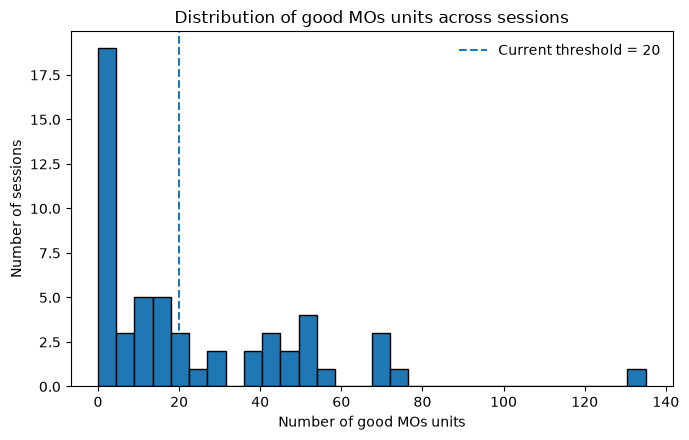

In [8]:
# ============================================================
# Inspect MOs good-unit distribution
# ============================================================

display(
    mos_session_inventory[
        "n_good_units_mos"
    ]
    .describe()
)

fig, ax = plt.subplots(
    figsize=(7.0, 4.5)
)

ax.hist(
    mos_session_inventory[
        "n_good_units_mos"
    ],
    bins=30,
    edgecolor="black",
)

ax.axvline(
    MIN_GOOD_UNITS,
    linestyle="--",
    linewidth=1.5,
    label=(
        f"Current threshold = "
        f"{MIN_GOOD_UNITS}"
    ),
)

ax.set_xlabel(
    "Number of good MOs units"
)

ax.set_ylabel(
    "Number of sessions"
)

ax.set_title(
    "Distribution of good MOs units across sessions"
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# Build contrast × side trial inventory for MOs sessions
# ============================================================

mos_session_ids = set(
    mos_session_inventory[
        "session"
    ]
    .astype(str)
)


mos_trial_inventory = (
    trial_df.loc[
        trial_df[
            "session"
        ]
        .astype(str)
        .isin(
            mos_session_ids
        )
    ]
    .groupby(
        [
            "subject",
            "session",
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(
        n_trials=(
            "n_trials",
            "sum",
        ),
        n_valid_trials=(
            "n_valid_trials",
            "sum",
        ),
    )
)


print(
    "MOs trial-condition rows:",
    len(
        mos_trial_inventory
    )
)


display(
    mos_trial_inventory.head(20)
)

MOs trial-condition rows: 550


,subject,session,gabor_stimulus_contrast,gabor_stimulus_side,n_trials,n_valid_trials
0,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,0.00,left,40,13
1,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,0.00,right,60,26
2,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,6.25,left,82,64
3,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,6.25,right,82,40
4,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,12.50,left,88,65
5,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,12.50,right,87,51
6,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,25.00,left,80,62
7,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,25.00,right,69,44
8,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,100.00,left,81,68
9,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,100.00,right,82,68


In [10]:
print(
    "Unique sessions in MOs trial inventory:",
    mos_trial_inventory[
        "session"
    ]
    .astype(str)
    .nunique()
)

print(
    "Unique subjects in MOs trial inventory:",
    mos_trial_inventory[
        "subject"
    ]
    .astype(str)
    .nunique()
)

Unique sessions in MOs trial inventory: 55
Unique subjects in MOs trial inventory: 36


In [11]:
# ============================================================
# 09. Inspect sensitivity to good-unit threshold
# ============================================================

unit_thresholds = [
    10,
    15,
    20,
    30,
    40,
]


threshold_summary_rows = []


for threshold in unit_thresholds:

    subset = (
        mos_session_inventory.loc[
            mos_session_inventory[
                "n_good_units_mos"
            ] >= threshold
        ]
    )

    threshold_summary_rows.append(
        {
            "min_good_units": threshold,
            "n_sessions": len(subset),
            "n_subjects": (
                subset[
                    "subject"
                ]
                .astype(str)
                .nunique()
            ),
        }
    )


unit_threshold_summary_df = pd.DataFrame(
    threshold_summary_rows
)

display(
    unit_threshold_summary_df
)

,min_good_units,n_sessions,n_subjects
0,10,30,25
1,15,26,22
2,20,22,18
3,30,19,16
4,40,15,13


In [12]:
# ============================================================
# 10. Build contrast × side valid-trial matrix
# ============================================================

analysis_trial_inventory = (
    mos_trial_inventory.loc[
        mos_trial_inventory[
            "gabor_stimulus_contrast"
        ]
        .isin(
            ANALYSIS_CONTRASTS
        )
        &
        mos_trial_inventory[
            "gabor_stimulus_side"
        ]
        .isin(
            ANALYSIS_SIDES
        )
    ]
    .copy()
)


print(
    "Sessions represented:",
    analysis_trial_inventory[
        "session"
    ]
    .astype(str)
    .nunique()
)

print(
    "Rows:",
    len(
        analysis_trial_inventory
    )
)

Sessions represented: 55
Rows: 440


In [13]:
trial_count_matrix = (
    analysis_trial_inventory
    .pivot_table(
        index=[
            "subject",
            "session",
        ],
        columns=[
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
        ],
        values="n_valid_trials",
        aggfunc="sum",
        fill_value=0,
    )
)

def contrast_label(
    contrast
):

    return (
        f"{contrast:g}"
        .replace(
            ".",
            "p",
        )
    )


trial_count_matrix.columns = [
    (
        "valid_"
        f"{contrast_label(contrast)}pct_"
        f"{side}"
    )
    for contrast, side
    in trial_count_matrix.columns
]


trial_count_matrix = (
    trial_count_matrix
    .reset_index()
)


display(
    trial_count_matrix.head(10)
)

,subject,session,valid_6p25pct_left,valid_6p25pct_right,valid_12p5pct_left,valid_12p5pct_right,valid_25pct_left,valid_25pct_right,valid_100pct_left,valid_100pct_right
0,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,64,40,65,51,62,44,68,68
1,CSH-ZAD-026,81a78eac-9d36-4f90-a73a-7eb3ad7f770b,132,65,113,78,128,79,124,104
2,CSHL049,d2918f52-8280-43c0-924b-029b2317e62c,63,59,84,55,74,54,68,69
3,CSHL049,d839491f-55d8-4cbe-a298-7839208ba12b,18,37,33,27,45,38,50,51
4,CSHL058,28741f91-c837-4147-939e-918d38d849f2,29,21,37,31,39,28,45,21
5,CSHL058,fb70ebf7-8175-42b0-9b7a-7c6e8612226e,50,56,60,48,57,44,59,69
6,CSHL060,1191f865-b10a-45c8-9c48-24a980fd9402,81,72,98,66,74,72,81,73
7,CSHL060,2e6e179c-fccc-4e8f-9448-ce5b6858a183,41,57,41,46,55,52,67,50
8,DY-011,36280321-555b-446d-9b7d-c2e17991e090,49,56,32,53,39,59,34,63
9,DY-011,cf43dbb1-6992-40ec-a5f9-e8e838d0f643,32,32,33,30,41,35,41,44


In [14]:
# ============================================================
# 11. Build full MOs eligibility table
# ============================================================

mos_eligibility_df = (
    mos_session_inventory
    .merge(
        trial_count_matrix,
        on=[
            "subject",
            "session",
        ],
        how="left",
        validate="one_to_one",
    )
)
trial_count_columns = [
    column
    for column
    in mos_eligibility_df.columns
    if column.startswith(
        "valid_"
    )
]


mos_eligibility_df[
    trial_count_columns
] = (
    mos_eligibility_df[
        trial_count_columns
    ]
    .fillna(0)
)

mos_eligibility_df[
    "min_valid_trials_across_conditions"
] = (
    mos_eligibility_df[
        trial_count_columns
    ]
    .min(
        axis=1
    )
)

In [15]:
mos_eligibility_df[
    "enough_good_units"
] = (
    mos_eligibility_df[
        "n_good_units_mos"
    ]
    >= MIN_GOOD_UNITS
)


mos_eligibility_df[
    "enough_trials"
] = (
    mos_eligibility_df[
        "min_valid_trials_across_conditions"
    ]
    >= MIN_VALID_TRIALS_PER_CONDITION
)


mos_eligibility_df[
    "eligible"
] = (
    mos_eligibility_df[
        "enough_good_units"
    ]
    &
    mos_eligibility_df[
        "enough_trials"
    ]
)
print(
    "Total MOs sessions:",
    len(
        mos_eligibility_df
    )
)

print(
    "Sessions with enough units:",
    mos_eligibility_df[
        "enough_good_units"
    ].sum()
)

print(
    "Sessions with enough trials:",
    mos_eligibility_df[
        "enough_trials"
    ].sum()
)

print(
    "Eligible sessions:",
    mos_eligibility_df[
        "eligible"
    ].sum()
)

print(
    "Eligible subjects:",
    mos_eligibility_df.loc[
        mos_eligibility_df[
            "eligible"
        ],
        "subject",
    ]
    .astype(str)
    .nunique()
)
eligibility_display_columns = [
    "subject",
    "session",
    "n_good_units_mos",
    "n_valid_trials",
    "valid_trial_fraction",
    "min_valid_trials_across_conditions",
    *trial_count_columns,
    "eligible",
]


display(
    mos_eligibility_df[
        eligibility_display_columns
    ]
    .sort_values(
        [
            "eligible",
            "n_good_units_mos",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)

Total MOs sessions: 55
Sessions with enough units: 22
Sessions with enough trials: 0
Eligible sessions: 0
Eligible subjects: 0


,subject,session,n_good_units_mos,n_valid_trials,valid_trial_fraction,min_valid_trials_across_conditions,valid_trial_fraction,valid_6p25pct_left,valid_6p25pct_right,valid_12p5pct_left,valid_12p5pct_right,valid_25pct_left,valid_25pct_right,valid_100pct_left,valid_100pct_right,eligible
0,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,135,545,0.710561,0.710561,0.710561,54,60,54,41,76,66,70,57,False
1,ZM-2240,d33baf74-263c-4b37-a0d0-b79dcb80a764,72,332,0.777518,0.777518,0.777518,27,43,34,36,39,42,35,44,False
2,CSHL058,fb70ebf7-8175-42b0-9b7a-7c6e8612226e,70,488,0.751926,0.751926,0.751926,50,56,60,48,57,44,59,69,False
3,NR-0027,0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde,69,618,0.518892,0.518892,0.518892,63,71,65,65,64,75,51,99,False
4,ZM-2241,ff4187b5-4176-4e39-8894-53a24b7cf36b,69,608,0.697248,0.697248,0.697248,75,56,90,60,68,56,72,67,False
5,CSHL049,d2918f52-8280-43c0-924b-029b2317e62c,54,587,0.701314,0.701314,0.701314,63,59,84,55,74,54,68,69,False
6,ZFM-02370,6f6d2c8e-28be-49f4-ae4d-06be2d3148c1,53,394,0.713768,0.713768,0.713768,50,24,55,34,52,45,53,47,False
7,KS023,aad23144-0e52-4eac-80c5-c4ee2decb198,52,484,0.755070,0.755070,0.755070,33,52,45,43,62,71,71,63,False
8,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,51,501,0.667111,0.667111,0.667111,64,40,65,51,62,44,68,68,False
9,CSHL060,2e6e179c-fccc-4e8f-9448-ce5b6858a183,50,451,0.815552,0.815552,0.815552,41,57,41,46,55,52,67,50,False


In [16]:
# ============================================================
# 12. Diagnose contrast and stimulus-side values
# ============================================================

print("Contrast values in MOs trial inventory:")

print(
    sorted(
        pd.to_numeric(
            mos_trial_inventory[
                "gabor_stimulus_contrast"
            ],
            errors="coerce",
        )
        .dropna()
        .unique()
    )
)


print("\nStimulus-side values:")

print(
    mos_trial_inventory[
        "gabor_stimulus_side"
    ]
    .astype(str)
    .str.strip()
    .value_counts(
        dropna=False
    )
)

Contrast values in MOs trial inventory:
[np.float64(0.0), np.float64(6.25), np.float64(12.5), np.float64(25.0), np.float64(100.0)]

Stimulus-side values:
gabor_stimulus_side
left     275
right    275
Name: count, dtype: int64


In [17]:
# ============================================================
# 13. Inspect valid-trial counts by contrast × side
# ============================================================

condition_coverage_df = (
    mos_trial_inventory
    .loc[
        mos_trial_inventory[
            "gabor_stimulus_contrast"
        ].isin(
            ANALYSIS_CONTRASTS
        )
    ]
    .groupby(
        [
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
        ],
        as_index=False,
    )
    .agg(
        n_sessions=(
            "session",
            "nunique",
        ),

        median_valid_trials=(
            "n_valid_trials",
            "median",
        ),

        min_valid_trials=(
            "n_valid_trials",
            "min",
        ),

        max_valid_trials=(
            "n_valid_trials",
            "max",
        ),

        n_sessions_ge_5=(
            "n_valid_trials",
            lambda x:
                int(
                    (x >= 5).sum()
                ),
        ),

        n_sessions_ge_10=(
            "n_valid_trials",
            lambda x:
                int(
                    (x >= 10).sum()
                ),
        ),

        n_sessions_ge_15=(
            "n_valid_trials",
            lambda x:
                int(
                    (x >= 15).sum()
                ),
        ),
    )
    .sort_values(
        [
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
        ]
    )
    .reset_index(
        drop=True
    )
)


display(
    condition_coverage_df
)

,gabor_stimulus_contrast,gabor_stimulus_side,n_sessions,median_valid_trials,min_valid_trials,max_valid_trials,n_sessions_ge_5,n_sessions_ge_10,n_sessions_ge_15
0,6.25,left,55,41.0,14,132,55,55,54
1,6.25,right,55,45.0,4,77,54,54,54
2,12.50,left,55,45.0,17,113,55,55,55
3,12.50,right,55,46.0,8,78,55,54,54
4,25.00,left,55,53.0,22,128,55,55,55
5,25.00,right,55,44.0,18,79,55,55,55
6,100.00,left,55,53.0,19,124,55,55,55
7,100.00,right,55,51.0,15,104,55,55,55


In [18]:
# ============================================================
# 14. Trial-count distribution in sessions with >=20 MOs units
# ============================================================

high_unit_sessions = (
    mos_eligibility_df.loc[
        mos_eligibility_df[
            "n_good_units_mos"
        ]
        >= MIN_GOOD_UNITS
    ]
    .copy()
)


print(
    "Sessions with >=20 good MOs units:",
    len(high_unit_sessions)
)

display(
    high_unit_sessions[
        "min_valid_trials_across_conditions"
    ].describe()
)


print("\nNumber of sessions surviving different trial thresholds:")

for threshold in [
    3,
    5,
    7,
    8,
    10,
    12,
    15,
]:

    n_sessions = (
        high_unit_sessions[
            "min_valid_trials_across_conditions"
        ]
        >= threshold
    ).sum()

    n_subjects = (
        high_unit_sessions.loc[
            high_unit_sessions[
                "min_valid_trials_across_conditions"
            ]
            >= threshold,
            "subject",
        ]
        .astype(str)
        .nunique()
    )

    print(
        f">= {threshold:2d} trials/condition: "
        f"{n_sessions:2d} sessions, "
        f"{n_subjects:2d} subjects"
    )

Sessions with >=20 good MOs units: 22


count    22.000000
mean      0.703366
std       0.079909
min       0.518892
25%       0.666376
50%       0.708311
75%       0.769931
max       0.815552
Name: min_valid_trials_across_conditions, dtype: float64


Number of sessions surviving different trial thresholds:
>=  3 trials/condition:  0 sessions,  0 subjects
>=  5 trials/condition:  0 sessions,  0 subjects
>=  7 trials/condition:  0 sessions,  0 subjects
>=  8 trials/condition:  0 sessions,  0 subjects
>= 10 trials/condition:  0 sessions,  0 subjects
>= 12 trials/condition:  0 sessions,  0 subjects
>= 15 trials/condition:  0 sessions,  0 subjects


In [19]:
# ============================================================
# FIX: define the 8 actual contrast × side trial-count columns
# ============================================================

trial_count_columns = [
    (
        "valid_"
        f"{contrast_label(contrast)}pct_"
        f"{side}"
    )
    for contrast in ANALYSIS_CONTRASTS
    for side in ANALYSIS_SIDES
]


print(
    "Trial-count columns used for eligibility:"
)

for column in trial_count_columns:
    print("  ", column)

Trial-count columns used for eligibility:
   valid_6p25pct_left
   valid_6p25pct_right
   valid_12p5pct_left
   valid_12p5pct_right
   valid_25pct_left
   valid_25pct_right
   valid_100pct_left
   valid_100pct_right


In [20]:
# ============================================================
# Recalculate minimum valid trials across the 8 conditions
# ============================================================

mos_eligibility_df[
    trial_count_columns
] = (
    mos_eligibility_df[
        trial_count_columns
    ]
    .fillna(0)
)


mos_eligibility_df[
    "min_valid_trials_across_conditions"
] = (
    mos_eligibility_df[
        trial_count_columns
    ]
    .min(
        axis=1
    )
)

display(
    mos_eligibility_df[
        "min_valid_trials_across_conditions"
    ]
    .describe()
)

count    55.000000
mean     37.818182
std      14.236223
min       4.000000
25%      28.500000
50%      34.000000
75%      48.000000
max      71.000000
Name: min_valid_trials_across_conditions, dtype: float64

In [21]:
# ============================================================
# Recalculate eligibility
# ============================================================

mos_eligibility_df[
    "enough_good_units"
] = (
    mos_eligibility_df[
        "n_good_units_mos"
    ]
    >= MIN_GOOD_UNITS
)


mos_eligibility_df[
    "enough_trials"
] = (
    mos_eligibility_df[
        "min_valid_trials_across_conditions"
    ]
    >= MIN_VALID_TRIALS_PER_CONDITION
)


mos_eligibility_df[
    "eligible"
] = (
    mos_eligibility_df[
        "enough_good_units"
    ]
    &
    mos_eligibility_df[
        "enough_trials"
    ]
)
print(
    "Total MOs sessions:",
    len(mos_eligibility_df)
)

print(
    "Sessions with enough units:",
    int(
        mos_eligibility_df[
            "enough_good_units"
        ].sum()
    )
)

print(
    "Sessions with enough trials:",
    int(
        mos_eligibility_df[
            "enough_trials"
        ].sum()
    )
)

print(
    "Eligible sessions:",
    int(
        mos_eligibility_df[
            "eligible"
        ].sum()
    )
)

print(
    "Eligible subjects:",
    mos_eligibility_df.loc[
        mos_eligibility_df[
            "eligible"
        ],
        "subject",
    ]
    .astype(str)
    .nunique()
)

Total MOs sessions: 55
Sessions with enough units: 22
Sessions with enough trials: 54
Eligible sessions: 22
Eligible subjects: 18


In [22]:
high_unit_sessions = (
    mos_eligibility_df.loc[
        mos_eligibility_df[
            "n_good_units_mos"
        ]
        >= MIN_GOOD_UNITS
    ]
    .copy()
)


print(
    "Sessions with >=20 good MOs units:",
    len(high_unit_sessions)
)

display(
    high_unit_sessions[
        "min_valid_trials_across_conditions"
    ]
    .describe()
)


print(
    "\nNumber of sessions surviving "
    "different trial thresholds:"
)


for threshold in [
    3,
    5,
    7,
    8,
    10,
    12,
    15,
]:

    condition_mask = (
        high_unit_sessions[
            "min_valid_trials_across_conditions"
        ]
        >= threshold
    )

    n_sessions = int(
        condition_mask.sum()
    )

    n_subjects = (
        high_unit_sessions.loc[
            condition_mask,
            "subject",
        ]
        .astype(str)
        .nunique()
    )

    print(
        f">= {threshold:2d} trials/condition: "
        f"{n_sessions:2d} sessions, "
        f"{n_subjects:2d} subjects"
    )

Sessions with >=20 good MOs units: 22


count    22.000000
mean     41.954545
std      14.025410
min      18.000000
25%      30.750000
50%      42.000000
75%      51.750000
max      71.000000
Name: min_valid_trials_across_conditions, dtype: float64


Number of sessions surviving different trial thresholds:
>=  3 trials/condition: 22 sessions, 18 subjects
>=  5 trials/condition: 22 sessions, 18 subjects
>=  7 trials/condition: 22 sessions, 18 subjects
>=  8 trials/condition: 22 sessions, 18 subjects
>= 10 trials/condition: 22 sessions, 18 subjects
>= 12 trials/condition: 22 sessions, 18 subjects
>= 15 trials/condition: 22 sessions, 18 subjects


In [23]:
# ============================================================
# 15. Save MOs eligibility tables
# ============================================================

eligible_mos_sessions = (
    mos_eligibility_df.loc[
        mos_eligibility_df["eligible"]
    ]
    .sort_values(
        [
            "subject",
            "session",
        ]
    )
    .reset_index(
        drop=True
    )
)


# Save full QC table
mos_eligibility_df.to_csv(
    TABLE_DIR
    / "mos_session_eligibility_all.csv",
    index=False,
)


# Save only sessions entering batch analysis
eligible_mos_sessions.to_csv(
    TABLE_DIR
    / "eligible_mos_sessions.csv",
    index=False,
)


print(
    "Eligible sessions:",
    len(eligible_mos_sessions)
)

print(
    "Eligible subjects:",
    eligible_mos_sessions[
        "subject"
    ]
    .astype(str)
    .nunique()
)

print(
    "\nSaved:"
)

print(
    TABLE_DIR
    / "mos_session_eligibility_all.csv"
)

print(
    TABLE_DIR
    / "eligible_mos_sessions.csv"
)

Eligible sessions: 22
Eligible subjects: 18

Saved:
D:\Ephys_analysis\ibl-population-dynamics\results\cross_session_MOs\tables\mos_session_eligibility_all.csv
D:\Ephys_analysis\ibl-population-dynamics\results\cross_session_MOs\tables\eligible_mos_sessions.csv


In [24]:
# ============================================================
# 16. Population-analysis parameters
# Keep identical to the single-session MOs analysis
# ============================================================

# Stimulus alignment window
TIME_START_S = -0.5
TIME_END_S = 1.0

# Spike-count binning
BIN_SIZE_S = 0.020

# Gaussian smoothing
SMOOTH_SIGMA_S = 0.040

# Baseline window
BASELINE_START_S = -0.35
BASELINE_END_S = -0.15

# Soft normalization constant
SOFT_NORMALIZATION_HZ = 5.0

# Main response window used for summary metrics
RESPONSE_START_S = 0.0
RESPONSE_END_S = 0.8


print(
    "Analysis window:",
    TIME_START_S,
    "to",
    TIME_END_S,
    "s",
)

print(
    "Bin size:",
    BIN_SIZE_S,
    "s",
)

print(
    "Gaussian sigma:",
    SMOOTH_SIGMA_S,
    "s",
)

print(
    "Baseline:",
    BASELINE_START_S,
    "to",
    BASELINE_END_S,
    "s",
)

Analysis window: -0.5 to 1.0 s
Bin size: 0.02 s
Gaussian sigma: 0.04 s
Baseline: -0.35 to -0.15 s


In [25]:
# ============================================================
# 17. Batch output configuration
# ============================================================

SAVE_SESSION_FIGURES = True

SAVE_SINGLE_UNIT_FIGURES = False

SAVE_PCA_TRAJECTORIES = True


def get_session_output_dir(
    session_id,
):

    session_dir = (
        SESSION_RESULT_DIR
        / str(session_id)
    )

    session_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    return session_dir

In [26]:
# ============================================================
# 18. Final batch cohort
#
# Run highest-unit sessions first.
# The prototype session should naturally be first.
# ============================================================

batch_sessions_df = (
    eligible_mos_sessions
    .sort_values(
        "n_good_units_mos",
        ascending=False,
    )
    .reset_index(drop=True)
)


display(
    batch_sessions_df[
        [
            "subject",
            "session",
            "n_good_units_mos",
            "min_valid_trials_across_conditions",
        ]
    ]
)


print(
    "Number of batch sessions:",
    len(batch_sessions_df),
)

print(
    "Number of subjects:",
    batch_sessions_df[
        "subject"
    ].nunique(),
)

print(
    "\nFirst session:"
)

display(
    batch_sessions_df.head(1)
)

,subject,session,n_good_units_mos,min_valid_trials_across_conditions
0,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,135,41
1,ZM-2240,d33baf74-263c-4b37-a0d0-b79dcb80a764,72,27
2,CSHL058,fb70ebf7-8175-42b0-9b7a-7c6e8612226e,70,44
3,ZM-2241,ff4187b5-4176-4e39-8894-53a24b7cf36b,69,56
4,NR-0027,0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde,69,51
5,CSHL049,d2918f52-8280-43c0-924b-029b2317e62c,54,54
6,ZFM-02370,6f6d2c8e-28be-49f4-ae4d-06be2d3148c1,53,24
7,KS023,aad23144-0e52-4eac-80c5-c4ee2decb198,52,33
8,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,51,40
9,CSHL060,2e6e179c-fccc-4e8f-9448-ce5b6858a183,50,41


Number of batch sessions: 22
Number of subjects: 18

First session:


,subject,session,asset_path,n_all_units_mos,n_good_units_mos,n_trials,n_valid_trials,valid_trial_fraction,median_rt_valid_s,accuracy_valid,valid_6p25pct_left,valid_6p25pct_right,valid_12p5pct_left,valid_12p5pct_right,valid_25pct_left,valid_25pct_right,valid_100pct_left,valid_100pct_right,min_valid_trials_across_conditions,enough_good_units,enough_trials,eligible
0,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,sub-SWC-038/sub-SWC-038_ses-4d8c7767-981c-4347...,1262,135,767,545,0.710561,0.303599,0.754128,54,60,54,41,76,66,70,57,41,True,True,True


In [28]:
# ============================================================
# 19. Additional imports for NWB batch analysis
# ============================================================

import re
import h5py
import remfile

from dandi.dandiapi import DandiAPIClient
from pynwb import NWBHDF5IO

from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA

from tqdm import tqdm

In [29]:
# ============================================================
# 20. DANDI and trial-QC configuration
# ============================================================

DANDISET_ID = "000409"
VERSION = "0.260309.1324"

GOOD_UNIT_SCORE = 1.0

MIN_RT_S = 0.08
MAX_RT_S = 2.00


REQUIRED_TRIAL_COLUMNS = [
    "gabor_stimulus_onset_time",
    "wheel_movement_onset_time",
    "choice_registration_time",
    "feedback_time",
    "mouse_wheel_choice",
    "probability_left",
    "is_mouse_rewarded",
]

In [30]:
# ============================================================
# 21A. Region / string helpers
# ============================================================

def scalar_to_text(value):

    if isinstance(value, bytes):
        return value.decode(
            "utf-8",
            errors="replace",
        )

    if pd.isna(value):
        return pd.NA

    return str(value)


def collapse_cortical_layer(
    region_name,
):

    if pd.isna(region_name):
        return pd.NA

    region_name = str(
        region_name
    ).strip()

    pattern = (
        r",?\s+layer\s+"
        r"(1|2/3|2|3|4|5|6a|6b|6)$"
    )

    return re.sub(
        pattern,
        "",
        region_name,
        flags=re.IGNORECASE,
    ).strip()

In [32]:
# ============================================================
# 21B. Unit → representative electrode
# ============================================================

def row_from_reference(
    reference,
    electrodes_df,
):

    if isinstance(
        reference,
        pd.Series,
    ):
        return reference


    if isinstance(
        reference,
        pd.DataFrame,
    ):

        if reference.empty:
            return None

        return reference.iloc[0]


    if isinstance(
        reference,
        (
            list,
            tuple,
            np.ndarray,
        ),
    ):

        values = np.asarray(
            reference
        ).ravel()

        if (
            len(values)
            and
            np.issubdtype(
                values.dtype,
                np.integer,
            )
        ):

            idx = int(
                values[0]
            )

            if (
                0
                <= idx
                < len(electrodes_df)
            ):

                return (
                    electrodes_df
                    .iloc[idx]
                )


    return None

def get_representative_electrode(
    nwbfile,
    electrodes_df,
    unit_index,
):

    # ----------------------------------------
    # First choice: max_electrode
    # ----------------------------------------

    max_ref = (
        nwbfile.units[
            "max_electrode"
        ][unit_index]
    )

    row = row_from_reference(
        max_ref,
        electrodes_df,
    )

    if row is not None:
        return row


    # ----------------------------------------
    # Fallback: electrodes linked to the unit
    # ----------------------------------------

    linked = (
        nwbfile.units[
            "electrodes"
        ][unit_index]
    )


    if isinstance(
        linked,
        pd.Series,
    ):

        linked_df = (
            linked
            .to_frame()
            .T
        )


    elif isinstance(
        linked,
        pd.DataFrame,
    ):

        linked_df = linked


    elif isinstance(
        linked,
        (
            list,
            tuple,
            np.ndarray,
        ),
    ):

        values = (
            np.asarray(
                linked
            )
            .ravel()
        )

        if (
            len(values)
            and
            np.issubdtype(
                values.dtype,
                np.integer,
            )
        ):

            values = (
                values
                .astype(int)
            )

            values = values[
                (values >= 0)
                &
                (
                    values
                    <
                    len(electrodes_df)
                )
            ]

            linked_df = (
                electrodes_df
                .iloc[values]
            )

        else:

            linked_df = (
                pd.DataFrame()
            )

    else:

        linked_df = (
            pd.DataFrame()
        )


    if (
        linked_df.empty
        or
        "location"
        not in linked_df.columns
    ):

        return None


    locations = (
        linked_df[
            "location"
        ]
        .dropna()
        .astype(str)
        .unique()
    )


    if len(locations) == 1:

        return (
            linked_df.iloc[0]
        )


    return None

In [33]:
# ============================================================
# 22. Trial preprocessing
# ============================================================

def prepare_valid_trials(
    nwbfile,
):

    if nwbfile.trials is None:
        raise ValueError(
            "No trials table."
        )


    trials = (
        nwbfile.trials
        .to_dataframe()
        .reset_index()
    )


    # ----------------------------------------
    # Standardize trial index
    # ----------------------------------------

    if "id" in trials.columns:

        trials = trials.rename(
            columns={
                "id":
                "trial_index"
            }
        )

    elif "index" in trials.columns:

        trials = trials.rename(
            columns={
                "index":
                "trial_index"
            }
        )

    else:

        trials.insert(
            0,
            "trial_index",
            np.arange(
                len(trials)
            ),
        )


    # ----------------------------------------
    # Check required columns
    # ----------------------------------------

    required_columns = (
        REQUIRED_TRIAL_COLUMNS
        +
        [
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
        ]
    )


    missing_columns = [
        column
        for column
        in required_columns
        if column
        not in trials.columns
    ]


    if missing_columns:

        raise ValueError(
            "Missing trial columns: "
            f"{missing_columns}"
        )


    # ----------------------------------------
    # Clean text columns
    # ----------------------------------------

    for column in [
        "gabor_stimulus_side",
        "mouse_wheel_choice",
    ]:

        trials[column] = (
            trials[column]
            .map(
                scalar_to_text
            )
        )


    trials[
        "gabor_stimulus_side"
    ] = (
        trials[
            "gabor_stimulus_side"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )


    # ----------------------------------------
    # Reaction time
    # ----------------------------------------

    trials[
        "reaction_time_s"
    ] = (
        pd.to_numeric(
            trials[
                "wheel_movement_onset_time"
            ],
            errors="coerce",
        )
        -
        pd.to_numeric(
            trials[
                "gabor_stimulus_onset_time"
            ],
            errors="coerce",
        )
    )


    # ----------------------------------------
    # Same valid-trial definition as before
    # ----------------------------------------

    trials[
        "has_required_events"
    ] = (
        trials[
            REQUIRED_TRIAL_COLUMNS
        ]
        .notna()
        .all(
            axis=1
        )
    )


    trials[
        "rt_in_range"
    ] = (
        trials[
            "reaction_time_s"
        ]
        .between(
            MIN_RT_S,
            MAX_RT_S,
            inclusive="both",
        )
    )


    trials[
        "is_valid_trial"
    ] = (
        trials[
            "has_required_events"
        ]
        &
        trials[
            "rt_in_range"
        ]
    )


    valid_trials_df = (
        trials.loc[
            trials[
                "is_valid_trial"
            ]
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    return (
        trials,
        valid_trials_df,
    )

In [34]:
# ============================================================
# 23. Select good units in TARGET_REGION
# ============================================================

def select_target_region_units(
    nwbfile,
    target_region,
):

    n_units = len(
        nwbfile.units
    )

    electrodes_df = (
        nwbfile.electrodes
        .to_dataframe()
    )


    quality = (
        pd.to_numeric(
            pd.Series(
                np.asarray(
                    nwbfile.units[
                        "ibl_quality_score"
                    ][:]
                )
            ),
            errors="coerce",
        )
    )


    if (
        "firing_rate"
        in nwbfile.units.colnames
    ):

        firing_rate = (
            pd.to_numeric(
                pd.Series(
                    np.asarray(
                        nwbfile.units[
                            "firing_rate"
                        ][:]
                    )
                ),
                errors="coerce",
            )
        )

    else:

        firing_rate = pd.Series(
            np.nan,
            index=np.arange(
                n_units
            ),
        )


    region_raw = []


    for unit_index in range(
        n_units
    ):

        electrode = (
            get_representative_electrode(
                nwbfile,
                electrodes_df,
                unit_index,
            )
        )


        if electrode is None:

            region_raw.append(
                pd.NA
            )

        else:

            region_raw.append(
                scalar_to_text(
                    electrode.get(
                        "location",
                        pd.NA,
                    )
                )
            )


    unit_metadata_df = (
        pd.DataFrame(
            {
                "unit_index":
                    np.arange(
                        n_units
                    ),

                "ibl_quality_score":
                    quality,

                "firing_rate":
                    firing_rate,

                "region_raw":
                    pd.Series(
                        region_raw,
                        dtype="string",
                    ),
            }
        )
    )


    unit_metadata_df[
        "region_parent"
    ] = (
        unit_metadata_df[
            "region_raw"
        ]
        .apply(
            collapse_cortical_layer
        )
        .astype(
            "string"
        )
    )


    unit_metadata_df[
        "is_good_unit"
    ] = (
        unit_metadata_df[
            "ibl_quality_score"
        ]
        .eq(
            GOOD_UNIT_SCORE
        )
    )


    selected_units_df = (
        unit_metadata_df.loc[
            unit_metadata_df[
                "is_good_unit"
            ]
            &
            unit_metadata_df[
                "region_parent"
            ].eq(
                target_region
            )
        ]
        .copy()
        .sort_values(
            "unit_index"
        )
        .reset_index(
            drop=True
        )
    )


    return (
        unit_metadata_df,
        selected_units_df,
    )

In [35]:
# ============================================================
# 24. Read spike times only for selected units
# ============================================================

def extract_selected_spike_times(
    nwbfile,
    selected_units_df,
):

    selected_spike_times = []


    for unit_index in (
        selected_units_df[
            "unit_index"
        ]
        .astype(int)
    ):

        spike_times = (
            np.asarray(
                nwbfile.units[
                    "spike_times"
                ][unit_index],
                dtype=float,
            )
        )

        selected_spike_times.append(
            spike_times
        )


    return selected_spike_times

In [36]:
# ============================================================
# 25. Stimulus-aligned spike binning
# ============================================================

def bin_stimulus_aligned_spikes(
    selected_spike_times,
    valid_trials_df,
):

    n_time_bins = int(
        round(
            (
                TIME_END_S
                -
                TIME_START_S
            )
            /
            BIN_SIZE_S
        )
    )


    time_bin_edges_s = (
        np.linspace(
            TIME_START_S,
            TIME_END_S,
            n_time_bins + 1,
        )
    )


    time_bin_centers_s = (
        (
            time_bin_edges_s[:-1]
            +
            time_bin_edges_s[1:]
        )
        /
        2
    )


    n_trials = len(
        valid_trials_df
    )

    n_units = len(
        selected_spike_times
    )


    spike_counts = np.zeros(
        (
            n_trials,
            n_units,
            n_time_bins,
        ),
        dtype=np.uint16,
    )


    alignment_times = (
        pd.to_numeric(
            valid_trials_df[
                "gabor_stimulus_onset_time"
            ],
            errors="coerce",
        )
        .to_numpy()
    )


    for trial_index, alignment_time in enumerate(
        alignment_times
    ):

        trial_edges = (
            alignment_time
            +
            time_bin_edges_s
        )


        for unit_index, spike_times in enumerate(
            selected_spike_times
        ):

            spike_counts[
                trial_index,
                unit_index,
                :,
            ] = np.histogram(
                spike_times,
                bins=trial_edges,
            )[0]


    firing_rates_hz = (
        spike_counts.astype(
            np.float32
        )
        /
        BIN_SIZE_S
    )


    smooth_sigma_bins = (
        SMOOTH_SIGMA_S
        /
        BIN_SIZE_S
    )


    smoothed_firing_rates_hz = (
        gaussian_filter1d(
            firing_rates_hz,
            sigma=smooth_sigma_bins,
            axis=2,
            mode="nearest",
            truncate=3.0,
        )
    )


    return {
        "spike_counts":
            spike_counts,

        "firing_rates_hz":
            firing_rates_hz,

        "smoothed_firing_rates_hz":
            smoothed_firing_rates_hz,

        "time_bin_edges_s":
            time_bin_edges_s,

        "time_bin_centers_s":
            time_bin_centers_s,
    }

In [37]:
# ============================================================
# 26. Build condition-averaged population states
# ============================================================

def compute_population_states(
    smoothed_firing_rates_hz,
    valid_trials_df,
    time_bin_centers_s,
):

    # --------------------------------------------------------
    # Time masks
    # --------------------------------------------------------

    baseline_mask = (
        (time_bin_centers_s >= BASELINE_START_S)
        &
        (time_bin_centers_s < BASELINE_END_S)
    )

    response_mask = (
        (time_bin_centers_s >= RESPONSE_START_S)
        &
        (time_bin_centers_s <= RESPONSE_END_S)
    )


    if not baseline_mask.any():
        raise ValueError(
            "Baseline window contains no time bins."
        )

    if not response_mask.any():
        raise ValueError(
            "Response window contains no time bins."
        )


    # --------------------------------------------------------
    # Common baseline for each unit
    #
    # Pool all valid trials and all baseline bins.
    # --------------------------------------------------------

    baseline_rates_hz = (
        smoothed_firing_rates_hz[
            :,
            :,
            baseline_mask,
        ]
    )


    baseline_mean_hz = (
        baseline_rates_hz
        .mean(
            axis=(0, 2)
        )
    )


    baseline_std_hz = (
        baseline_rates_hz
        .std(
            axis=(0, 2),
            ddof=1,
        )
    )


    # --------------------------------------------------------
    # Trial metadata
    # --------------------------------------------------------

    contrast_values = (
        pd.to_numeric(
            valid_trials_df[
                "gabor_stimulus_contrast"
            ],
            errors="coerce",
        )
        .to_numpy()
    )


    stimulus_sides = (
        valid_trials_df[
            "gabor_stimulus_side"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .to_numpy()
    )


    # --------------------------------------------------------
    # Mean population activity for each contrast × side
    # --------------------------------------------------------

    condition_mean_rates_hz = {}
    condition_trial_counts = {}

    condition_keys = []


    for contrast in ANALYSIS_CONTRASTS:

        for side in ANALYSIS_SIDES:

            trial_mask = (
                np.isclose(
                    contrast_values,
                    contrast,
                )
                &
                (
                    stimulus_sides
                    == side
                )
            )


            n_trials = int(
                trial_mask.sum()
            )


            if (
                n_trials
                <
                MIN_VALID_TRIALS_PER_CONDITION
            ):

                raise ValueError(
                    f"Too few trials for "
                    f"{contrast}% {side}: "
                    f"{n_trials}"
                )


            condition_mean_rates_hz[
                (contrast, side)
            ] = (
                smoothed_firing_rates_hz[
                    trial_mask,
                    :,
                    :,
                ]
                .mean(
                    axis=0
                )
            )


            condition_trial_counts[
                (contrast, side)
            ] = n_trials


            condition_keys.append(
                (
                    contrast,
                    side,
                )
            )


    # --------------------------------------------------------
    # Stack:
    #
    # condition × unit × time
    # --------------------------------------------------------

    condition_stack_hz = np.stack(
        [
            condition_mean_rates_hz[
                key
            ]
            for key
            in condition_keys
        ],
        axis=0,
    )


    # --------------------------------------------------------
    # Soft normalization
    #
    # scale_i =
    # response range_i + 5 Hz
    # --------------------------------------------------------

    unit_rate_range_hz = (
        condition_stack_hz.max(
            axis=(0, 2)
        )
        -
        condition_stack_hz.min(
            axis=(0, 2)
        )
    )


    soft_scale_hz = (
        unit_rate_range_hz
        +
        SOFT_NORMALIZATION_HZ
    )


    soft_normalized_condition_rates = (
        (
            condition_stack_hz
            -
            baseline_mean_hz[
                None,
                :,
                None,
            ]
        )
        /
        soft_scale_hz[
            None,
            :,
            None,
        ]
    )


    # --------------------------------------------------------
    # Convert to:
    #
    # time × unit
    #
    # for each condition.
    # --------------------------------------------------------

    condition_soft_trajectories = {}


    for condition_index, key in enumerate(
        condition_keys
    ):

        condition_soft_trajectories[
            key
        ] = (
            soft_normalized_condition_rates[
                condition_index,
                :,
                :,
            ]
            .T
        )


    return {
        "baseline_mask":
            baseline_mask,

        "response_mask":
            response_mask,

        "baseline_mean_hz":
            baseline_mean_hz,

        "baseline_std_hz":
            baseline_std_hz,

        "condition_keys":
            condition_keys,

        "condition_trial_counts":
            condition_trial_counts,

        "condition_mean_rates_hz":
            condition_mean_rates_hz,

        "condition_stack_hz":
            condition_stack_hz,

        "soft_scale_hz":
            soft_scale_hz,

        "soft_normalized_condition_rates":
            soft_normalized_condition_rates,

        "condition_soft_trajectories":
            condition_soft_trajectories,
    }

In [38]:
# ============================================================
# 27. PCA trajectories
# ============================================================

def compute_pca_trajectories(
    population_states,
):

    soft_rates = (
        population_states[
            "soft_normalized_condition_rates"
        ]
    )

    condition_keys = (
        population_states[
            "condition_keys"
        ]
    )


    n_conditions = (
        soft_rates.shape[0]
    )

    n_units = (
        soft_rates.shape[1]
    )

    n_time_bins = (
        soft_rates.shape[2]
    )


    # --------------------------------------------------------
    # condition × unit × time
    #
    # →
    #
    # (condition × time) × unit
    # --------------------------------------------------------

    pca_input = (
        soft_rates
        .transpose(
            0,
            2,
            1,
        )
        .reshape(
            -1,
            n_units,
        )
    )


    pca = PCA(
        n_components=3
    )


    pca_scores = (
        pca.fit_transform(
            pca_input
        )
        .reshape(
            n_conditions,
            n_time_bins,
            3,
        )
    )


    condition_pca_trajectories = {}


    for condition_index, key in enumerate(
        condition_keys
    ):

        condition_pca_trajectories[
            key
        ] = (
            pca_scores[
                condition_index,
                :,
                :,
            ]
        )


    return {
        "pca":
            pca,

        "explained_variance_ratio":
            pca.explained_variance_ratio_.copy(),

        "condition_pca_trajectories":
            condition_pca_trajectories,
    }

In [39]:
# ============================================================
# 28. Left-right population separation
# ============================================================

def compute_separation_metrics(
    population_states,
):

    trajectories = (
        population_states[
            "condition_soft_trajectories"
        ]
    )

    baseline_mask = (
        population_states[
            "baseline_mask"
        ]
    )


    separation_results = {}


    for contrast in ANALYSIS_CONTRASTS:

        left_states = (
            trajectories[
                (contrast, "left")
            ]
        )

        right_states = (
            trajectories[
                (contrast, "right")
            ]
        )


        difference = (
            left_states
            -
            right_states
        )


        # Ordinary Euclidean distance
        euclidean = (
            np.linalg.norm(
                difference,
                axis=1,
            )
        )


        # RMS distance:
        # normalized for population dimensionality
        rms = (
            np.sqrt(
                np.mean(
                    difference ** 2,
                    axis=1,
                )
            )
        )


        euclidean_baseline = float(
            euclidean[
                baseline_mask
            ].mean()
        )


        rms_baseline = float(
            rms[
                baseline_mask
            ].mean()
        )


        separation_results[
            contrast
        ] = {

            "euclidean":
                euclidean,

            "euclidean_baseline":
                euclidean_baseline,

            "euclidean_baseline_corrected":
                (
                    euclidean
                    -
                    euclidean_baseline
                ),

            "rms":
                rms,

            "rms_baseline":
                rms_baseline,

            "rms_baseline_corrected":
                (
                    rms
                    -
                    rms_baseline
                ),
        }


    return separation_results

In [40]:
# ============================================================
# 29. Population trajectory excursion
# ============================================================

def compute_excursion_metrics(
    population_states,
):

    trajectories = (
        population_states[
            "condition_soft_trajectories"
        ]
    )

    baseline_mask = (
        population_states[
            "baseline_mask"
        ]
    )


    excursion_results = {}


    for contrast in ANALYSIS_CONTRASTS:

        excursion_results[
            contrast
        ] = {}


        for side in ANALYSIS_SIDES:

            trajectory = (
                trajectories[
                    (contrast, side)
                ]
            )


            baseline_centroid = (
                trajectory[
                    baseline_mask,
                    :
                ]
                .mean(
                    axis=0
                )
            )


            difference = (
                trajectory
                -
                baseline_centroid[
                    None,
                    :
                ]
            )


            euclidean = (
                np.linalg.norm(
                    difference,
                    axis=1,
                )
            )


            rms = (
                np.sqrt(
                    np.mean(
                        difference ** 2,
                        axis=1,
                    )
                )
            )


            euclidean_baseline = float(
                euclidean[
                    baseline_mask
                ].mean()
            )


            rms_baseline = float(
                rms[
                    baseline_mask
                ].mean()
            )


            excursion_results[
                contrast
            ][side] = {

                "euclidean":
                    euclidean,

                "euclidean_baseline_corrected":
                    (
                        euclidean
                        -
                        euclidean_baseline
                    ),

                "rms":
                    rms,

                "rms_baseline_corrected":
                    (
                        rms
                        -
                        rms_baseline
                    ),

                "baseline_rms":
                    rms_baseline,
            }


        # ----------------------------------------------------
        # Mean across left and right stimulus conditions
        # ----------------------------------------------------

        excursion_results[
            contrast
        ][
            "mean_rms"
        ] = (
            (
                excursion_results[
                    contrast
                ][
                    "left"
                ][
                    "rms"
                ]
                +
                excursion_results[
                    contrast
                ][
                    "right"
                ][
                    "rms"
                ]
            )
            /
            2
        )


        excursion_results[
            contrast
        ][
            "mean_rms_baseline_corrected"
        ] = (
            (
                excursion_results[
                    contrast
                ][
                    "left"
                ][
                    "rms_baseline_corrected"
                ]
                +
                excursion_results[
                    contrast
                ][
                    "right"
                ][
                    "rms_baseline_corrected"
                ]
            )
            /
            2
        )


    return excursion_results

In [41]:
# ============================================================
# 30A. Summarize a time-resolved metric
# ============================================================

def summarize_response_curve(
    curve,
    time_bin_centers_s,
    response_mask,
):

    response_curve = (
        curve[
            response_mask
        ]
    )

    response_times = (
        time_bin_centers_s[
            response_mask
        ]
    )


    peak_local_index = int(
        np.argmax(
            response_curve
        )
    )


    return {
        "peak":
            float(
                response_curve[
                    peak_local_index
                ]
            ),

        "peak_time_s":
            float(
                response_times[
                    peak_local_index
                ]
            ),

        "mean":
            float(
                response_curve.mean()
            ),

        "auc":
            float(
                np.trapezoid(
                    response_curve,
                    response_times,
                )
            ),
    }

In [42]:
# ============================================================
# 30B. Build numerical result tables
# ============================================================

def build_result_tables(
    session_row,
    selected_units_df,
    valid_trials_df,
    time_bin_centers_s,
    population_states,
    pca_results,
    separation_results,
    excursion_results,
):

    subject = str(
        session_row[
            "subject"
        ]
    )

    session = str(
        session_row[
            "session"
        ]
    )


    response_mask = (
        population_states[
            "response_mask"
        ]
    )


    # ========================================================
    # 1. Session summary
    # ========================================================

    reward_numeric = (
        pd.to_numeric(
            valid_trials_df[
                "is_mouse_rewarded"
            ],
            errors="coerce",
        )
    )


    explained = (
        pca_results[
            "explained_variance_ratio"
        ]
    )


    session_summary_df = (
        pd.DataFrame(
            [
                {
                    "subject":
                        subject,

                    "session":
                        session,

                    "region":
                        TARGET_REGION,

                    "n_good_units":
                        len(
                            selected_units_df
                        ),

                    "n_valid_trials":
                        len(
                            valid_trials_df
                        ),

                    "median_rt_valid_s":
                        float(
                            valid_trials_df[
                                "reaction_time_s"
                            ]
                            .median()
                        ),

                    "accuracy_valid":
                        float(
                            reward_numeric.mean()
                        ),

                    "pc1_explained_variance":
                        float(
                            explained[0]
                        ),

                    "pc2_explained_variance":
                        float(
                            explained[1]
                        ),

                    "pc3_explained_variance":
                        float(
                            explained[2]
                        ),
                }
            ]
        )
    )


    # ========================================================
    # 2. Condition summary
    #
    # one row = session × contrast
    # ========================================================

    condition_rows = []


    for contrast in ANALYSIS_CONTRASTS:

        separation_curve = (
            separation_results[
                contrast
            ][
                "rms_baseline_corrected"
            ]
        )


        excursion_curve = (
            excursion_results[
                contrast
            ][
                "mean_rms_baseline_corrected"
            ]
        )


        separation_summary = (
            summarize_response_curve(
                separation_curve,
                time_bin_centers_s,
                response_mask,
            )
        )


        excursion_summary = (
            summarize_response_curve(
                excursion_curve,
                time_bin_centers_s,
                response_mask,
            )
        )


        condition_rows.append(
            {
                "subject":
                    subject,

                "session":
                    session,

                "contrast":
                    contrast,

                "n_left_trials":
                    population_states[
                        "condition_trial_counts"
                    ][
                        (contrast, "left")
                    ],

                "n_right_trials":
                    population_states[
                        "condition_trial_counts"
                    ][
                        (contrast, "right")
                    ],

                # --------------------------------------------
                # Separation
                # --------------------------------------------

                "baseline_separation_rms":
                    separation_results[
                        contrast
                    ][
                        "rms_baseline"
                    ],

                "peak_evoked_separation_rms":
                    separation_summary[
                        "peak"
                    ],

                "peak_separation_time_s":
                    separation_summary[
                        "peak_time_s"
                    ],

                "mean_evoked_separation_rms":
                    separation_summary[
                        "mean"
                    ],

                "auc_evoked_separation_rms":
                    separation_summary[
                        "auc"
                    ],

                # --------------------------------------------
                # Excursion
                # --------------------------------------------

                "peak_evoked_excursion_rms":
                    excursion_summary[
                        "peak"
                    ],

                "peak_excursion_time_s":
                    excursion_summary[
                        "peak_time_s"
                    ],

                "mean_evoked_excursion_rms":
                    excursion_summary[
                        "mean"
                    ],

                "auc_evoked_excursion_rms":
                    excursion_summary[
                        "auc"
                    ],
            }
        )


    condition_summary_df = (
        pd.DataFrame(
            condition_rows
        )
    )


    # ========================================================
    # 3. Timecourse table
    #
    # one row = session × contrast × time
    # ========================================================

    timecourse_rows = []


    for contrast in ANALYSIS_CONTRASTS:

        for time_index, time_s in enumerate(
            time_bin_centers_s
        ):

            timecourse_rows.append(
                {
                    "subject":
                        subject,

                    "session":
                        session,

                    "contrast":
                        contrast,

                    "time_s":
                        float(
                            time_s
                        ),

                    "separation_euclidean":
                        float(
                            separation_results[
                                contrast
                            ][
                                "euclidean"
                            ][
                                time_index
                            ]
                        ),

                    "separation_rms":
                        float(
                            separation_results[
                                contrast
                            ][
                                "rms"
                            ][
                                time_index
                            ]
                        ),

                    "separation_rms_baseline_corrected":
                        float(
                            separation_results[
                                contrast
                            ][
                                "rms_baseline_corrected"
                            ][
                                time_index
                            ]
                        ),

                    "excursion_left_rms":
                        float(
                            excursion_results[
                                contrast
                            ][
                                "left"
                            ][
                                "rms"
                            ][
                                time_index
                            ]
                        ),

                    "excursion_right_rms":
                        float(
                            excursion_results[
                                contrast
                            ][
                                "right"
                            ][
                                "rms"
                            ][
                                time_index
                            ]
                        ),

                    "excursion_mean_rms":
                        float(
                            excursion_results[
                                contrast
                            ][
                                "mean_rms"
                            ][
                                time_index
                            ]
                        ),

                    "excursion_mean_rms_baseline_corrected":
                        float(
                            excursion_results[
                                contrast
                            ][
                                "mean_rms_baseline_corrected"
                            ][
                                time_index
                            ]
                        ),
                }
            )


    timecourse_df = pd.DataFrame(
        timecourse_rows
    )


    # ========================================================
    # 4. PCA trajectory table
    #
    # one row = session × contrast × side × time
    # ========================================================

    pca_rows = []


    for contrast in ANALYSIS_CONTRASTS:

        for side in ANALYSIS_SIDES:

            trajectory = (
                pca_results[
                    "condition_pca_trajectories"
                ][
                    (contrast, side)
                ]
            )


            for time_index, time_s in enumerate(
                time_bin_centers_s
            ):

                pca_rows.append(
                    {
                        "subject":
                            subject,

                        "session":
                            session,

                        "contrast":
                            contrast,

                        "side":
                            side,

                        "time_s":
                            float(
                                time_s
                            ),

                        "PC1":
                            float(
                                trajectory[
                                    time_index,
                                    0,
                                ]
                            ),

                        "PC2":
                            float(
                                trajectory[
                                    time_index,
                                    1,
                                ]
                            ),

                        "PC3":
                            float(
                                trajectory[
                                    time_index,
                                    2,
                                ]
                            ),
                    }
                )


    pca_trajectories_df = (
        pd.DataFrame(
            pca_rows
        )
    )


    return {
        "session_summary":
            session_summary_df,

        "condition_summary":
            condition_summary_df,

        "timecourse":
            timecourse_df,

        "pca_trajectories":
            pca_trajectories_df,
    }

In [43]:
# ============================================================
# 31. Session output paths
# ============================================================

def get_session_paths(
    session_id,
):

    session_dir = (
        SESSION_RESULT_DIR
        /
        str(session_id)
    )

    extraction_dir = (
        session_dir
        /
        "extracted"
    )

    tables_dir = (
        session_dir
        /
        "tables"
    )

    figures_dir = (
        session_dir
        /
        "figures"
    )


    for folder in [
        session_dir,
        extraction_dir,
        tables_dir,
        figures_dir,
    ]:

        folder.mkdir(
            parents=True,
            exist_ok=True,
        )


    return {
        "session_dir":
            session_dir,

        "extraction_dir":
            extraction_dir,

        "tables_dir":
            tables_dir,

        "figures_dir":
            figures_dir,

        "extraction_marker":
            session_dir
            /
            "EXTRACTION_COMPLETE.txt",

        "analysis_marker":
            session_dir
            /
            "ANALYSIS_COMPLETE.txt",
    }

In [44]:
# ============================================================
# 32. Save extraction checkpoint
# ============================================================

def save_extraction_checkpoint(
    session_row,
    all_trials_df,
    valid_trials_df,
    selected_units_df,
    selected_spike_times,
):

    session = str(
        session_row[
            "session"
        ]
    )


    paths = get_session_paths(
        session
    )


    extraction_dir = (
        paths[
            "extraction_dir"
        ]
    )


    # --------------------------------------------------------
    # Tables
    # --------------------------------------------------------

    selected_units_df.to_csv(
        extraction_dir
        /
        "selected_units.csv",
        index=False,
    )


    valid_trials_df.to_csv(
        extraction_dir
        /
        "valid_trials.csv",
        index=False,
    )


    # Small enough to keep, useful for QC later
    all_trials_df.to_csv(
        extraction_dir
        /
        "all_trials.csv",
        index=False,
    )


    # --------------------------------------------------------
    # Variable-length spike-time arrays
    # --------------------------------------------------------

    spike_payload = {
        "unit_indices":
            selected_units_df[
                "unit_index"
            ]
            .astype(int)
            .to_numpy()
    }


    for local_unit_index, spike_times in enumerate(
        selected_spike_times
    ):

        spike_payload[
            f"spikes_{local_unit_index:04d}"
        ] = (
            np.asarray(
                spike_times,
                dtype=np.float64,
            )
        )


    np.savez_compressed(
        extraction_dir
        /
        "selected_unit_spike_times.npz",
        **spike_payload,
    )


    # --------------------------------------------------------
    # Only write COMPLETE after all three files are saved
    # --------------------------------------------------------

    paths[
        "extraction_marker"
    ].write_text(
        "complete\n",
        encoding="utf-8",
    )

In [45]:
# ============================================================
# 33. Load extraction checkpoint
# ============================================================

def load_extraction_checkpoint(
    session_id,
):

    paths = get_session_paths(
        session_id
    )


    extraction_dir = (
        paths[
            "extraction_dir"
        ]
    )


    selected_units_df = (
        pd.read_csv(
            extraction_dir
            /
            "selected_units.csv"
        )
    )


    valid_trials_df = (
        pd.read_csv(
            extraction_dir
            /
            "valid_trials.csv"
        )
    )


    all_trials_df = (
        pd.read_csv(
            extraction_dir
            /
            "all_trials.csv"
        )
    )


    spike_file = (
        extraction_dir
        /
        "selected_unit_spike_times.npz"
    )


    with np.load(
        spike_file
    ) as data:

        unit_indices = (
            data[
                "unit_indices"
            ]
            .astype(int)
        )


        selected_spike_times = [
            np.asarray(
                data[
                    f"spikes_{i:04d}"
                ],
                dtype=float,
            )
            for i in range(
                len(
                    unit_indices
                )
            )
        ]


    # --------------------------------------------------------
    # Critical mapping QC
    # --------------------------------------------------------

    expected_indices = (
        selected_units_df[
            "unit_index"
        ]
        .astype(int)
        .to_numpy()
    )


    if not np.array_equal(
        unit_indices,
        expected_indices,
    ):

        raise ValueError(
            "Saved spike-time unit order "
            "does not match selected_units.csv."
        )


    return {
        "all_trials_df":
            all_trials_df,

        "valid_trials_df":
            valid_trials_df,

        "selected_units_df":
            selected_units_df,

        "selected_spike_times":
            selected_spike_times,
    }

In [46]:
CACHE_DIR = (
    PROJECT_DIR
    / "cache"
    / "remfile"
)

CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

In [47]:
# ============================================================
# 34. Extract one session from remote NWB
# ============================================================

def extract_one_session_from_dandi(
    session_row,
    dandiset,
):

    subject = str(
        session_row[
            "subject"
        ]
    )

    session = str(
        session_row[
            "session"
        ]
    )

    asset_path = str(
        session_row[
            "asset_path"
        ]
    )


    print(
        f"\nExtracting {subject} | {session}"
    )


    rem_file = None
    h5py_file = None
    io = None


    try:

        # ----------------------------------------------------
        # Remote access
        # ----------------------------------------------------

        asset = (
            dandiset
            .get_asset_by_path(
                path=asset_path
            )
        )


        s3_url = (
            asset.get_content_url(
                follow_redirects=1,
                strip_query=True,
            )
        )


        disk_cache = (
            remfile.DiskCache(
                str(
                    CACHE_DIR
                )
            )
        )


        rem_file = (
            remfile.File(
                s3_url,
                disk_cache=disk_cache,
            )
        )


        h5py_file = (
            h5py.File(
                rem_file,
                mode="r",
            )
        )


        io = NWBHDF5IO(
            file=h5py_file,
            load_namespaces=True,
        )


        nwbfile = (
            io.read()
        )


        # ----------------------------------------------------
        # Trials
        # ----------------------------------------------------

        (
            all_trials_df,
            valid_trials_df,
        ) = (
            prepare_valid_trials(
                nwbfile
            )
        )


        # ----------------------------------------------------
        # Units
        # ----------------------------------------------------

        (
            unit_metadata_df,
            selected_units_df,
        ) = (
            select_target_region_units(
                nwbfile,
                TARGET_REGION,
            )
        )


        expected_units = int(
            session_row[
                "n_good_units_mos"
            ]
        )

        actual_units = len(
            selected_units_df
        )


        if (
            actual_units
            != expected_units
        ):

            raise ValueError(
                f"MOs good-unit mismatch: "
                f"inventory={expected_units}, "
                f"extracted={actual_units}"
            )


        if (
            actual_units
            < MIN_GOOD_UNITS
        ):

            raise ValueError(
                f"Only {actual_units} "
                f"good MOs units."
            )


        # ----------------------------------------------------
        # Spike times
        # ----------------------------------------------------

        selected_spike_times = (
            extract_selected_spike_times(
                nwbfile,
                selected_units_df,
            )
        )


        # ----------------------------------------------------
        # Save BEFORE closing remote resources
        # ----------------------------------------------------

        save_extraction_checkpoint(
            session_row=session_row,
            all_trials_df=all_trials_df,
            valid_trials_df=valid_trials_df,
            selected_units_df=selected_units_df,
            selected_spike_times=selected_spike_times,
        )


        print(
            "Extraction saved:",
            actual_units,
            "units |",
            len(valid_trials_df),
            "valid trials",
        )


        return {
            "all_trials_df":
                all_trials_df,

            "valid_trials_df":
                valid_trials_df,

            "selected_units_df":
                selected_units_df,

            "selected_spike_times":
                selected_spike_times,
        }


    finally:

        for obj in (
            io,
            h5py_file,
            rem_file,
        ):

            if obj is not None:

                try:
                    obj.close()

                except Exception:
                    pass


        print(
            "Remote NWB resources closed."
        )

In [48]:
# ============================================================
# 35. Analyze one locally extracted session
# ============================================================

def analyze_extracted_session(
    session_row,
    extracted_data,
):

    session = str(
        session_row[
            "session"
        ]
    )


    paths = get_session_paths(
        session
    )


    selected_units_df = (
        extracted_data[
            "selected_units_df"
        ]
    )

    valid_trials_df = (
        extracted_data[
            "valid_trials_df"
        ]
    )

    selected_spike_times = (
        extracted_data[
            "selected_spike_times"
        ]
    )


    print(
        f"Analyzing {session}"
    )


    # --------------------------------------------------------
    # Spike binning + smoothing
    # --------------------------------------------------------

    binned = (
        bin_stimulus_aligned_spikes(
            selected_spike_times,
            valid_trials_df,
        )
    )


    time_bin_centers_s = (
        binned[
            "time_bin_centers_s"
        ]
    )


    # --------------------------------------------------------
    # Population states
    # --------------------------------------------------------

    population_states = (
        compute_population_states(
            binned[
                "smoothed_firing_rates_hz"
            ],
            valid_trials_df,
            time_bin_centers_s,
        )
    )


    # --------------------------------------------------------
    # PCA
    # --------------------------------------------------------

    pca_results = (
        compute_pca_trajectories(
            population_states
        )
    )


    # --------------------------------------------------------
    # Separation
    # --------------------------------------------------------

    separation_results = (
        compute_separation_metrics(
            population_states
        )
    )


    # --------------------------------------------------------
    # Excursion
    # --------------------------------------------------------

    excursion_results = (
        compute_excursion_metrics(
            population_states
        )
    )


    # --------------------------------------------------------
    # Build tables
    # --------------------------------------------------------

    result_tables = (
        build_result_tables(
            session_row=session_row,
            selected_units_df=selected_units_df,
            valid_trials_df=valid_trials_df,
            time_bin_centers_s=time_bin_centers_s,
            population_states=population_states,
            pca_results=pca_results,
            separation_results=separation_results,
            excursion_results=excursion_results,
        )
    )


    # --------------------------------------------------------
    # Save numerical outputs
    # --------------------------------------------------------

    for table_name, dataframe in (
        result_tables.items()
    ):

        dataframe.to_csv(
            paths[
                "tables_dir"
            ]
            /
            f"{table_name}.csv",
            index=False,
        )


    # --------------------------------------------------------
    # Mark complete only after all tables exist
    # --------------------------------------------------------

    paths[
        "analysis_marker"
    ].write_text(
        "complete\n",
        encoding="utf-8",
    )


    print(
        "Analysis tables saved."
    )


    return {
        **result_tables,

        "time_bin_centers_s":
            time_bin_centers_s,

        "population_states":
            population_states,

        "pca_results":
            pca_results,

        "separation_results":
            separation_results,

        "excursion_results":
            excursion_results,
    }

In [49]:
# ============================================================
# 36. Process one session end-to-end
# ============================================================

def process_one_mos_session(
    session_row,
    dandiset,
):

    session = str(
        session_row[
            "session"
        ]
    )


    paths = get_session_paths(
        session
    )


    # ========================================================
    # Case 1:
    # Full analysis already completed
    # ========================================================

    if (
        paths[
            "analysis_marker"
        ]
        .exists()
    ):

        print(
            f"\nSKIP {session}: "
            f"analysis already complete."
        )

        return {
            "status":
                "already_complete",

            "session":
                session,
        }


    # ========================================================
    # Case 2:
    # Remote extraction already completed
    # ========================================================

    if (
        paths[
            "extraction_marker"
        ]
        .exists()
    ):

        print(
            f"\nLoading local extraction: "
            f"{session}"
        )

        extracted_data = (
            load_extraction_checkpoint(
                session
            )
        )


    # ========================================================
    # Case 3:
    # Need remote extraction
    # ========================================================

    else:

        extracted_data = (
            extract_one_session_from_dandi(
                session_row=session_row,
                dandiset=dandiset,
            )
        )


    # ========================================================
    # Local numerical analysis
    # ========================================================

    analysis_result = (
        analyze_extracted_session(
            session_row=session_row,
            extracted_data=extracted_data,
        )
    )


    # Do NOT return the large arrays to the batch loop.
    # Everything important is already saved.

    return {
        "status":
            "completed",

        "session":
            session,

        "session_summary":
            analysis_result[
                "session_summary"
            ],

        "condition_summary":
            analysis_result[
                "condition_summary"
            ],

        "timecourse":
            analysis_result[
                "timecourse"
            ],
    }

In [60]:
# ============================================================
# 37A. Batch run configuration
# ============================================================

# First run:
#   1    -> run only the first session
#
# Full batch:
#   None -> process all eligible sessions
#
# Completed sessions will be skipped automatically.

MAX_BATCH_SESSIONS = None

In [61]:
# ============================================================
# 37B. Select sessions for this run
# ============================================================

if MAX_BATCH_SESSIONS is None:

    sessions_to_run = (
        batch_sessions_df.copy()
    )

else:

    sessions_to_run = (
        batch_sessions_df
        .head(
            MAX_BATCH_SESSIONS
        )
        .copy()
    )


print(
    "Sessions in this run:",
    len(sessions_to_run)
)

display(
    sessions_to_run[
        [
            "subject",
            "session",
            "n_good_units_mos",
            "min_valid_trials_across_conditions",
        ]
    ]
)

Sessions in this run: 22


,subject,session,n_good_units_mos,min_valid_trials_across_conditions
0,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,135,41
1,ZM-2240,d33baf74-263c-4b37-a0d0-b79dcb80a764,72,27
2,CSHL058,fb70ebf7-8175-42b0-9b7a-7c6e8612226e,70,44
3,ZM-2241,ff4187b5-4176-4e39-8894-53a24b7cf36b,69,56
4,NR-0027,0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde,69,51
5,CSHL049,d2918f52-8280-43c0-924b-029b2317e62c,54,54
6,ZFM-02370,6f6d2c8e-28be-49f4-ae4d-06be2d3148c1,53,24
7,KS023,aad23144-0e52-4eac-80c5-c4ee2decb198,52,33
8,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,51,40
9,CSHL060,2e6e179c-fccc-4e8f-9448-ce5b6858a183,50,41


In [62]:
# ============================================================
# 37C. Batch log paths
# ============================================================

BATCH_LOG_PATH = (
    TABLE_DIR
    /
    "batch_run_log.csv"
)

FAILED_SESSION_PATH = (
    TABLE_DIR
    /
    "failed_sessions.csv"
)

In [67]:
# ============================================================
# 37D. Run MOs cross-session batch
# ============================================================

batch_log_rows = []


with DandiAPIClient() as client:

    dandiset = (
        client.get_dandiset(
            dandiset_id=DANDISET_ID,
            version_id=VERSION,
        )
    )


    for _, session_row in tqdm(
        sessions_to_run.iterrows(),
        total=len(sessions_to_run),
        desc="MOs batch",
    ):

        subject = str(
            session_row[
                "subject"
            ]
        )

        session = str(
            session_row[
                "session"
            ]
        )


        print(
            "\n"
            + "=" * 70
        )

        print(
            f"Subject: {subject}"
        )

        print(
            f"Session: {session}"
        )

        print(
            "Expected good MOs units:",
            int(
                session_row[
                    "n_good_units_mos"
                ]
            )
        )

        print(
            "=" * 70
        )


        result = None
        try:

            result = (
                process_one_mos_session(
                    session_row=session_row,
                    dandiset=dandiset,
                )
            )


            batch_log_rows.append(
                {
                    "subject":
                        subject,

                    "session":
                        session,

                    "status":
                        result[
                            "status"
                        ],

                    "error_type":
                        pd.NA,

                    "error_message":
                        pd.NA,
                }
            )


            print(
                f"SUCCESS: {session}"
            )


        except Exception as error:

            print(
                f"FAILED: {session}"
            )

            print(
                type(error).__name__,
                ":",
                str(error),
            )


            batch_log_rows.append(
                {
                    "subject":
                        subject,

                    "session":
                        session,

                    "status":
                        "failed",

                    "error_type":
                        type(
                            error
                        ).__name__,

                    "error_message":
                        str(
                            error
                        ),
                }
            )


        # ----------------------------------------------------
        # Save log after EVERY session
        # ----------------------------------------------------

        current_batch_log_df = (
            pd.DataFrame(
                batch_log_rows
            )
        )


        current_batch_log_df.to_csv(
            BATCH_LOG_PATH,
            index=False,
        )


        # ----------------------------------------------------
        # Release temporary Python objects
        # ----------------------------------------------------

        if result is not None:
            del result


        gc.collect()

MOs batch:   9%|▉         | 2/22 [00:00<00:01, 11.60it/s]


Subject: SWC-038
Session: 4d8c7767-981c-4347-8e5e-5d5fffe38534
Expected good MOs units: 135

SKIP 4d8c7767-981c-4347-8e5e-5d5fffe38534: analysis already complete.
SUCCESS: 4d8c7767-981c-4347-8e5e-5d5fffe38534

Subject: ZM-2240
Session: d33baf74-263c-4b37-a0d0-b79dcb80a764
Expected good MOs units: 72

SKIP d33baf74-263c-4b37-a0d0-b79dcb80a764: analysis already complete.
SUCCESS: d33baf74-263c-4b37-a0d0-b79dcb80a764

Subject: CSHL058
Session: fb70ebf7-8175-42b0-9b7a-7c6e8612226e
Expected good MOs units: 70

SKIP fb70ebf7-8175-42b0-9b7a-7c6e8612226e: analysis already complete.
SUCCESS: fb70ebf7-8175-42b0-9b7a-7c6e8612226e


MOs batch:  18%|█▊        | 4/22 [00:00<00:01, 11.39it/s]


Subject: ZM-2241
Session: ff4187b5-4176-4e39-8894-53a24b7cf36b
Expected good MOs units: 69

SKIP ff4187b5-4176-4e39-8894-53a24b7cf36b: analysis already complete.
SUCCESS: ff4187b5-4176-4e39-8894-53a24b7cf36b

Subject: NR-0027
Session: 0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde
Expected good MOs units: 69

SKIP 0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde: analysis already complete.
SUCCESS: 0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde

Subject: CSHL049
Session: d2918f52-8280-43c0-924b-029b2317e62c
Expected good MOs units: 54

Extracting CSHL049 | d2918f52-8280-43c0-924b-029b2317e62c


MOs batch:  18%|█▊        | 4/22 [00:13<00:01, 11.39it/s]

Extraction saved: 54 units | 587 valid trials
Remote NWB resources closed.
Analyzing d2918f52-8280-43c0-924b-029b2317e62c


... (10 outputs left out)

MOs batch:  91%|█████████ | 20/22 [10:59<00:16,  8.45s/it]


SKIP 2c44a360-5a56-4971-8009-f469fb59de98: analysis already complete.
SUCCESS: 2c44a360-5a56-4971-8009-f469fb59de98

Subject: SWC-043
Session: f3ce3197-d534-4618-bf81-b687555d1883
Expected good MOs units: 26

SKIP f3ce3197-d534-4618-bf81-b687555d1883: analysis already complete.
SUCCESS: f3ce3197-d534-4618-bf81-b687555d1883

Subject: KS023
Session: a4000c2f-fa75-4b3e-8f06-a7cf599b87ad
Expected good MOs units: 22

SKIP a4000c2f-fa75-4b3e-8f06-a7cf599b87ad: analysis already complete.
SUCCESS: a4000c2f-fa75-4b3e-8f06-a7cf599b87ad


MOs batch: 100%|██████████| 22/22 [11:00<00:00, 30.00s/it]


Subject: ZM-1897
Session: dd4da095-4a99-4bf3-9727-f735077dba66
Expected good MOs units: 20

SKIP dd4da095-4a99-4bf3-9727-f735077dba66: analysis already complete.
SUCCESS: dd4da095-4a99-4bf3-9727-f735077dba66


In [68]:
# ============================================================
# 37E. Batch run summary
# ============================================================

batch_log_df = (
    pd.read_csv(
        BATCH_LOG_PATH
    )
)


display(
    batch_log_df
)


print(
    "\nStatus counts:"
)

display(
    batch_log_df[
        "status"
    ]
    .value_counts(
        dropna=False
    )
)

,subject,session,status,error_type,error_message
0,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,already_complete,NaN,NaN
1,ZM-2240,d33baf74-263c-4b37-a0d0-b79dcb80a764,already_complete,NaN,NaN
2,CSHL058,fb70ebf7-8175-42b0-9b7a-7c6e8612226e,already_complete,NaN,NaN
3,ZM-2241,ff4187b5-4176-4e39-8894-53a24b7cf36b,already_complete,NaN,NaN
4,NR-0027,0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde,already_complete,NaN,NaN
5,CSHL049,d2918f52-8280-43c0-924b-029b2317e62c,completed,NaN,NaN
6,ZFM-02370,6f6d2c8e-28be-49f4-ae4d-06be2d3148c1,already_complete,NaN,NaN
7,KS023,aad23144-0e52-4eac-80c5-c4ee2decb198,already_complete,NaN,NaN
8,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,already_complete,NaN,NaN
9,CSHL060,2e6e179c-fccc-4e8f-9448-ce5b6858a183,already_complete,NaN,NaN



Status counts:


status
already_complete    21
completed            1
Name: count, dtype: int64

In [65]:
# ============================================================
# 38A. Inspect completed session outputs
# ============================================================

first_session = str(
    sessions_to_run.iloc[0][
        "session"
    ]
)


first_paths = (
    get_session_paths(
        first_session
    )
)


print(
    "Session directory:"
)

print(
    first_paths[
        "session_dir"
    ]
)


print(
    "\nExtraction complete:",
    first_paths[
        "extraction_marker"
    ]
    .exists()
)


print(
    "Analysis complete:",
    first_paths[
        "analysis_marker"
    ]
    .exists()
)

Session directory:
D:\Ephys_analysis\ibl-population-dynamics\results\cross_session_MOs\session_results\4d8c7767-981c-4347-8e5e-5d5fffe38534

Extraction complete: True
Analysis complete: True


In [66]:
print(
    "\nExtracted files:"
)

for file_path in (
    first_paths[
        "extraction_dir"
    ]
    .iterdir()
):

    print(
        " ",
        file_path.name
    )


Extracted files:
  all_trials.csv
  selected_units.csv
  selected_unit_spike_times.npz
  valid_trials.csv


In [58]:
print(
    "\nAnalysis tables:"
)

for file_path in (
    first_paths[
        "tables_dir"
    ]
    .iterdir()
):

    print(
        " ",
        file_path.name
    )


Analysis tables:
  condition_summary.csv
  pca_trajectories.csv
  session_summary.csv
  timecourse.csv


In [59]:
# ============================================================
# 39. Sanity check first completed session
# ============================================================

first_session_summary = pd.read_csv(
    first_paths[
        "tables_dir"
    ]
    /
    "session_summary.csv"
)


first_condition_summary = pd.read_csv(
    first_paths[
        "tables_dir"
    ]
    /
    "condition_summary.csv"
)


first_timecourse = pd.read_csv(
    first_paths[
        "tables_dir"
    ]
    /
    "timecourse.csv"
)


first_pca = pd.read_csv(
    first_paths[
        "tables_dir"
    ]
    /
    "pca_trajectories.csv"
)

display(
    first_session_summary
)


display(
    first_condition_summary
)
print(
    "Condition-summary rows:",
    len(
        first_condition_summary
    )
)

print(
    "Timecourse rows:",
    len(
        first_timecourse
    )
)

print(
    "PCA rows:",
    len(
        first_pca
    )
)
# ============================================================
# Numerical QC
# ============================================================

numeric_qc_columns = [
    "peak_evoked_separation_rms",
    "mean_evoked_separation_rms",
    "auc_evoked_separation_rms",
    "peak_evoked_excursion_rms",
    "mean_evoked_excursion_rms",
    "auc_evoked_excursion_rms",
]


print(
    first_condition_summary[
        numeric_qc_columns
    ]
    .isna()
    .sum()
)


print(
    "\nAll finite:"
)

print(
    np.isfinite(
        first_condition_summary[
            numeric_qc_columns
        ]
        .to_numpy(
            dtype=float
        )
    )
    .all()
)

,subject,session,region,n_good_units,n_valid_trials,median_rt_valid_s,accuracy_valid,pc1_explained_variance,pc2_explained_variance,pc3_explained_variance
0,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,Secondary motor area,135,545,0.303599,0.754128,0.572868,0.141638,0.067451


,subject,session,contrast,n_left_trials,n_right_trials,baseline_separation_rms,peak_evoked_separation_rms,peak_separation_time_s,mean_evoked_separation_rms,auc_evoked_separation_rms,peak_evoked_excursion_rms,peak_excursion_time_s,mean_evoked_excursion_rms,auc_evoked_excursion_rms
0,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,6.25,54,60,0.073887,0.042916,0.45,0.024523,0.019391,0.123898,0.53,0.089648,0.070284
1,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,12.50,54,41,0.081149,0.049459,0.37,0.028471,0.022375,0.179760,0.39,0.127273,0.100183
2,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,25.00,76,66,0.071974,0.135507,0.25,0.058888,0.046679,0.266102,0.31,0.177106,0.139849
3,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,100.00,70,57,0.070617,0.128446,0.23,0.070254,0.055902,0.313956,0.29,0.219305,0.173515


Condition-summary rows: 4
Timecourse rows: 300
PCA rows: 600
peak_evoked_separation_rms    0
mean_evoked_separation_rms    0
auc_evoked_separation_rms     0
peak_evoked_excursion_rms     0
mean_evoked_excursion_rms     0
auc_evoked_excursion_rms      0
dtype: int64

All finite:
True


In [69]:
# ============================================================
# 43. Aggregate completed MOs session results
# ============================================================

all_session_summaries = []
all_condition_summaries = []
all_timecourses = []


completed_session_ids = []


for _, session_row in (
    batch_sessions_df.iterrows()
):

    session = str(
        session_row[
            "session"
        ]
    )

    paths = (
        get_session_paths(
            session
        )
    )


    if not (
        paths[
            "analysis_marker"
        ]
        .exists()
    ):

        continue


    tables_dir = (
        paths[
            "tables_dir"
        ]
    )


    all_session_summaries.append(
        pd.read_csv(
            tables_dir
            /
            "session_summary.csv"
        )
    )


    all_condition_summaries.append(
        pd.read_csv(
            tables_dir
            /
            "condition_summary.csv"
        )
    )


    all_timecourses.append(
        pd.read_csv(
            tables_dir
            /
            "timecourse.csv"
        )
    )


    completed_session_ids.append(
        session
    )

In [70]:
cross_session_summary_df = (
    pd.concat(
        all_session_summaries,
        ignore_index=True,
    )
)


cross_condition_summary_df = (
    pd.concat(
        all_condition_summaries,
        ignore_index=True,
    )
)


cross_timecourse_df = (
    pd.concat(
        all_timecourses,
        ignore_index=True,
    )
)

In [71]:
cross_session_summary_df.to_csv(
    TABLE_DIR
    /
    "cross_session_summary.csv",
    index=False,
)


cross_condition_summary_df.to_csv(
    TABLE_DIR
    /
    "cross_condition_summary.csv",
    index=False,
)


cross_timecourse_df.to_csv(
    TABLE_DIR
    /
    "cross_timecourse.csv",
    index=False,
)

In [72]:
# ============================================================
# 44. Cross-session aggregation QC
# ============================================================

print(
    "Completed sessions:",
    cross_session_summary_df[
        "session"
    ]
    .astype(str)
    .nunique()
)

print(
    "Subjects:",
    cross_session_summary_df[
        "subject"
    ]
    .astype(str)
    .nunique()
)

print(
    "Session-summary rows:",
    len(
        cross_session_summary_df
    )
)

print(
    "Condition-summary rows:",
    len(
        cross_condition_summary_df
    )
)

print(
    "Timecourse rows:",
    len(
        cross_timecourse_df
    )
)

Completed sessions: 22
Subjects: 18
Session-summary rows: 22
Condition-summary rows: 88
Timecourse rows: 6600


In [73]:
assert (
    cross_session_summary_df[
        "session"
    ]
    .nunique()
    == 22
)

assert (
    cross_session_summary_df[
        "subject"
    ]
    .nunique()
    == 18
)

assert (
    len(
        cross_condition_summary_df
    )
    == 22
    * len(
        ANALYSIS_CONTRASTS
    )
)

assert (
    len(
        cross_timecourse_df
    )
    == 22
    * len(
        ANALYSIS_CONTRASTS
    )
    * 75
)

print(
    "Cross-session QC passed."
)

Cross-session QC passed.


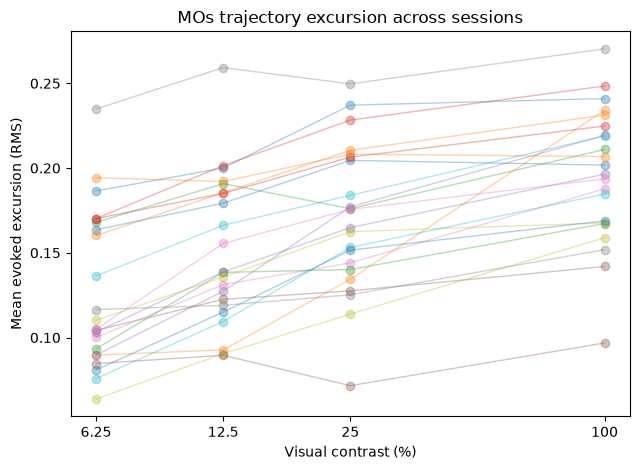

In [74]:
# ============================================================
# 45A. Session-level excursion summary
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 4.8)
)


for session, session_df in (
    cross_condition_summary_df
    .groupby(
        "session"
    )
):

    session_df = (
        session_df
        .sort_values(
            "contrast"
        )
    )


    ax.plot(
        session_df[
            "contrast"
        ],
        session_df[
            "mean_evoked_excursion_rms"
        ],
        marker="o",
        alpha=0.35,
        linewidth=1.0,
    )


ax.set_xlabel(
    "Visual contrast (%)"
)

ax.set_ylabel(
    "Mean evoked excursion (RMS)"
)

ax.set_title(
    "MOs trajectory excursion across sessions"
)

ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    ANALYSIS_CONTRASTS
)

ax.set_xticklabels(
    [
        f"{contrast:g}"
        for contrast
        in ANALYSIS_CONTRASTS
    ]
)

plt.tight_layout()
plt.show()

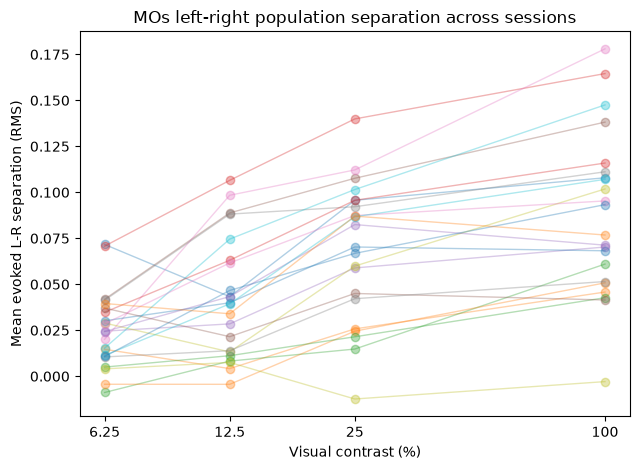

In [75]:
# ============================================================
# 45B. Session-level left-right separation
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 4.8)
)


for session, session_df in (
    cross_condition_summary_df
    .groupby(
        "session"
    )
):

    session_df = (
        session_df
        .sort_values(
            "contrast"
        )
    )


    ax.plot(
        session_df[
            "contrast"
        ],
        session_df[
            "mean_evoked_separation_rms"
        ],
        marker="o",
        alpha=0.35,
        linewidth=1.0,
    )


ax.set_xlabel(
    "Visual contrast (%)"
)

ax.set_ylabel(
    "Mean evoked L-R separation (RMS)"
)

ax.set_title(
    "MOs left-right population separation across sessions"
)

ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    ANALYSIS_CONTRASTS
)

ax.set_xticklabels(
    [
        f"{contrast:g}"
        for contrast
        in ANALYSIS_CONTRASTS
    ]
)

plt.tight_layout()
plt.show()

In [76]:
# ============================================================
# 46A. Number of sessions per subject
# ============================================================

sessions_per_subject = (
    cross_session_summary_df
    .groupby(
        "subject"
    )[
        "session"
    ]
    .nunique()
    .sort_values(
        ascending=False
    )
)


display(
    sessions_per_subject
)

print(
    "Subjects with >1 session:",
    (
        sessions_per_subject
        > 1
    ).sum()
)

subject
CSHL049        2
KS023          2
SWC-038        2
NR-0027        2
CSH-ZAD-024    1
CSHL058        1
DY-014         1
CSHL060        1
KS046          1
NYU-30         1
SWC-043        1
UCLA034        1
ZFM-01936      1
ZFM-02370      1
ZM-1897        1
ZM-2240        1
ZM-2241        1
ZM-2245        1
Name: session, dtype: int64

Subjects with >1 session: 4


In [77]:
# ============================================================
# 46B. Subject-level condition summary
# ============================================================

subject_condition_summary_df = (
    cross_condition_summary_df
    .groupby(
        [
            "subject",
            "contrast",
        ],
        as_index=False,
    )
    .agg(
        n_sessions=(
            "session",
            "nunique",
        ),

        mean_evoked_excursion_rms=(
            "mean_evoked_excursion_rms",
            "mean",
        ),

        peak_evoked_excursion_rms=(
            "peak_evoked_excursion_rms",
            "mean",
        ),

        auc_evoked_excursion_rms=(
            "auc_evoked_excursion_rms",
            "mean",
        ),

        mean_evoked_separation_rms=(
            "mean_evoked_separation_rms",
            "mean",
        ),

        peak_evoked_separation_rms=(
            "peak_evoked_separation_rms",
            "mean",
        ),

        auc_evoked_separation_rms=(
            "auc_evoked_separation_rms",
            "mean",
        ),
    )
)

In [78]:
print(
    "Subjects:",
    subject_condition_summary_df[
        "subject"
    ].nunique()
)

print(
    "Rows:",
    len(
        subject_condition_summary_df
    )
)

Subjects: 18
Rows: 72


In [79]:
subject_condition_summary_df.to_csv(
    TABLE_DIR
    /
    "subject_condition_summary.csv",
    index=False,
)

In [80]:
# ============================================================
# 47A. Group summary: trajectory excursion
# ============================================================

excursion_group_df = (
    subject_condition_summary_df
    .groupby(
        "contrast",
        as_index=False,
    )
    .agg(
        mean=(
            "mean_evoked_excursion_rms",
            "mean",
        ),

        std=(
            "mean_evoked_excursion_rms",
            "std",
        ),

        n_subjects=(
            "subject",
            "nunique",
        ),
    )
)


excursion_group_df[
    "sem"
] = (
    excursion_group_df[
        "std"
    ]
    /
    np.sqrt(
        excursion_group_df[
            "n_subjects"
        ]
    )
)


display(
    excursion_group_df
)

,contrast,mean,std,n_subjects,sem
0,6.25,0.129887,0.046300,18,0.010913
1,12.50,0.153272,0.043999,18,0.010371
2,25.00,0.170473,0.043806,18,0.010325
3,100.00,0.194711,0.041269,18,0.009727


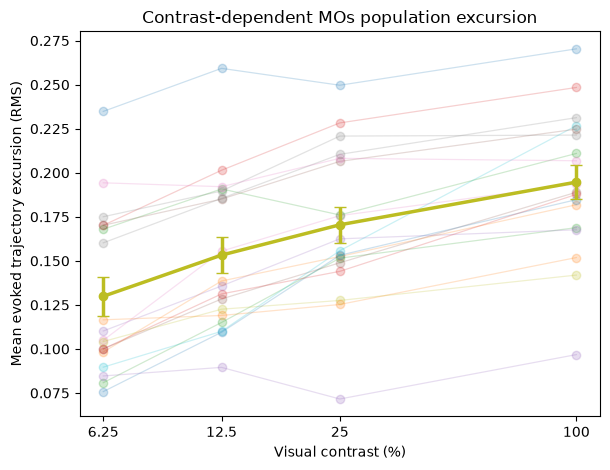

In [81]:
fig, ax = plt.subplots(
    figsize=(6.2, 4.8)
)


# ------------------------------------------------------------
# Individual subjects
# ------------------------------------------------------------

for subject, subject_df in (
    subject_condition_summary_df
    .groupby(
        "subject"
    )
):

    subject_df = (
        subject_df
        .sort_values(
            "contrast"
        )
    )


    ax.plot(
        subject_df[
            "contrast"
        ],
        subject_df[
            "mean_evoked_excursion_rms"
        ],
        marker="o",
        alpha=0.22,
        linewidth=0.9,
    )


# ------------------------------------------------------------
# Group mean ± SEM
# ------------------------------------------------------------

ax.errorbar(
    excursion_group_df[
        "contrast"
    ],
    excursion_group_df[
        "mean"
    ],
    yerr=excursion_group_df[
        "sem"
    ],
    marker="o",
    linewidth=2.5,
    capsize=4,
)


ax.set_xlabel(
    "Visual contrast (%)"
)

ax.set_ylabel(
    "Mean evoked trajectory excursion (RMS)"
)

ax.set_title(
    "Contrast-dependent MOs population excursion"
)


ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    ANALYSIS_CONTRASTS
)

ax.set_xticklabels(
    [
        f"{contrast:g}"
        for contrast
        in ANALYSIS_CONTRASTS
    ]
)


plt.tight_layout()


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "01_cross_subject_excursion_vs_contrast.png",
    dpi=300,
    bbox_inches="tight",
)


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "01_cross_subject_excursion_vs_contrast.pdf",
    bbox_inches="tight",
)


plt.show()

In [82]:
# ============================================================
# 48A. Group summary: left-right separation
# ============================================================

separation_group_df = (
    subject_condition_summary_df
    .groupby(
        "contrast",
        as_index=False,
    )
    .agg(
        mean=(
            "mean_evoked_separation_rms",
            "mean",
        ),

        std=(
            "mean_evoked_separation_rms",
            "std",
        ),

        n_subjects=(
            "subject",
            "nunique",
        ),
    )
)


separation_group_df[
    "sem"
] = (
    separation_group_df[
        "std"
    ]
    /
    np.sqrt(
        separation_group_df[
            "n_subjects"
        ]
    )
)


display(
    separation_group_df
)

,contrast,mean,std,n_subjects,sem
0,6.25,0.024702,0.020283,18,0.004781
1,12.50,0.044576,0.033462,18,0.007887
2,25.00,0.069309,0.038179,18,0.008999
3,100.00,0.089431,0.045637,18,0.010757


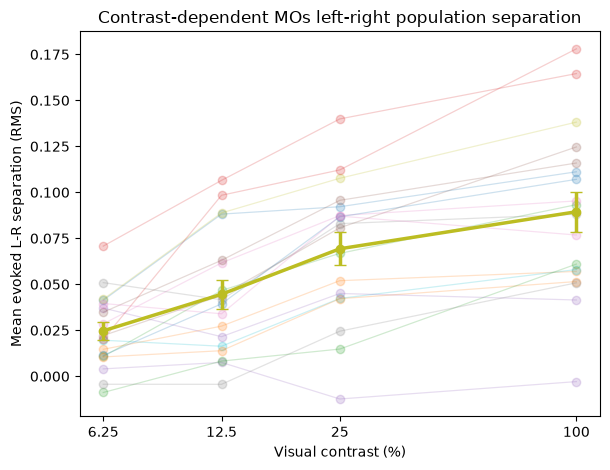

In [83]:
fig, ax = plt.subplots(
    figsize=(6.2, 4.8)
)


for subject, subject_df in (
    subject_condition_summary_df
    .groupby(
        "subject"
    )
):

    subject_df = (
        subject_df
        .sort_values(
            "contrast"
        )
    )


    ax.plot(
        subject_df[
            "contrast"
        ],
        subject_df[
            "mean_evoked_separation_rms"
        ],
        marker="o",
        alpha=0.22,
        linewidth=0.9,
    )


ax.errorbar(
    separation_group_df[
        "contrast"
    ],
    separation_group_df[
        "mean"
    ],
    yerr=separation_group_df[
        "sem"
    ],
    marker="o",
    linewidth=2.5,
    capsize=4,
)


ax.set_xlabel(
    "Visual contrast (%)"
)

ax.set_ylabel(
    "Mean evoked L-R separation (RMS)"
)

ax.set_title(
    "Contrast-dependent MOs left-right population separation"
)


ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    ANALYSIS_CONTRASTS
)

ax.set_xticklabels(
    [
        f"{contrast:g}"
        for contrast
        in ANALYSIS_CONTRASTS
    ]
)


plt.tight_layout()


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "02_cross_subject_separation_vs_contrast.png",
    dpi=300,
    bbox_inches="tight",
)


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "02_cross_subject_separation_vs_contrast.pdf",
    bbox_inches="tight",
)


plt.show()

In [84]:
# ============================================================
# 49A. Subject-level timecourses
# ============================================================

subject_timecourse_df = (
    cross_timecourse_df
    .groupby(
        [
            "subject",
            "contrast",
            "time_s",
        ],
        as_index=False,
    )
    .agg(
        separation_rms=(
            "separation_rms_baseline_corrected",
            "mean",
        ),

        excursion_rms=(
            "excursion_mean_rms_baseline_corrected",
            "mean",
        ),

        n_sessions=(
            "session",
            "nunique",
        ),
    )
)

In [85]:
subject_timecourse_df.to_csv(
    TABLE_DIR
    /
    "subject_timecourse.csv",
    index=False,
)

In [86]:
# ============================================================
# 49B. Excursion timecourses across subjects
# ============================================================

excursion_time_group_df = (
    subject_timecourse_df
    .groupby(
        [
            "contrast",
            "time_s",
        ],
        as_index=False,
    )
    .agg(
        mean=(
            "excursion_rms",
            "mean",
        ),

        std=(
            "excursion_rms",
            "std",
        ),

        n_subjects=(
            "subject",
            "nunique",
        ),
    )
)


excursion_time_group_df[
    "sem"
] = (
    excursion_time_group_df[
        "std"
    ]
    /
    np.sqrt(
        excursion_time_group_df[
            "n_subjects"
        ]
    )
)

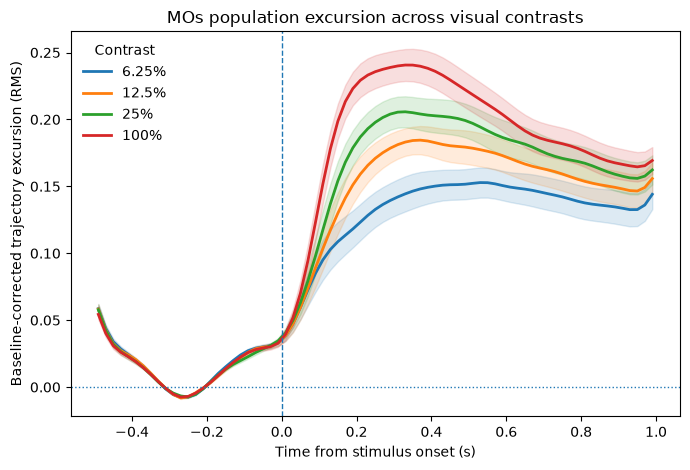

In [87]:
fig, ax = plt.subplots(
    figsize=(7.0, 4.8)
)


for contrast in ANALYSIS_CONTRASTS:

    plot_df = (
        excursion_time_group_df.loc[
            excursion_time_group_df[
                "contrast"
            ]
            .eq(
                contrast
            )
        ]
        .sort_values(
            "time_s"
        )
    )


    line = ax.plot(
        plot_df[
            "time_s"
        ],
        plot_df[
            "mean"
        ],
        linewidth=2.0,
        label=(
            f"{contrast:g}%"
        ),
    )[0]


    ax.fill_between(
        plot_df[
            "time_s"
        ],
        plot_df[
            "mean"
        ]
        -
        plot_df[
            "sem"
        ],
        plot_df[
            "mean"
        ]
        +
        plot_df[
            "sem"
        ],
        alpha=0.15,
        color=line.get_color(),
    )


ax.axvline(
    0,
    linestyle="--",
    linewidth=1.0,
)


ax.axhline(
    0,
    linestyle=":",
    linewidth=1.0,
)


ax.set_xlabel(
    "Time from stimulus onset (s)"
)

ax.set_ylabel(
    "Baseline-corrected trajectory excursion (RMS)"
)

ax.set_title(
    "MOs population excursion across visual contrasts"
)

ax.legend(
    title="Contrast",
    frameon=False,
)


plt.tight_layout()


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "03_cross_subject_excursion_timecourse.png",
    dpi=300,
    bbox_inches="tight",
)


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "03_cross_subject_excursion_timecourse.pdf",
    bbox_inches="tight",
)


plt.show()

In [88]:
# ============================================================
# 50. Left-right separation timecourses across subjects
# ============================================================

separation_time_group_df = (
    subject_timecourse_df
    .groupby(
        [
            "contrast",
            "time_s",
        ],
        as_index=False,
    )
    .agg(
        mean=(
            "separation_rms",
            "mean",
        ),

        std=(
            "separation_rms",
            "std",
        ),

        n_subjects=(
            "subject",
            "nunique",
        ),
    )
)


separation_time_group_df[
    "sem"
] = (
    separation_time_group_df[
        "std"
    ]
    /
    np.sqrt(
        separation_time_group_df[
            "n_subjects"
        ]
    )
)

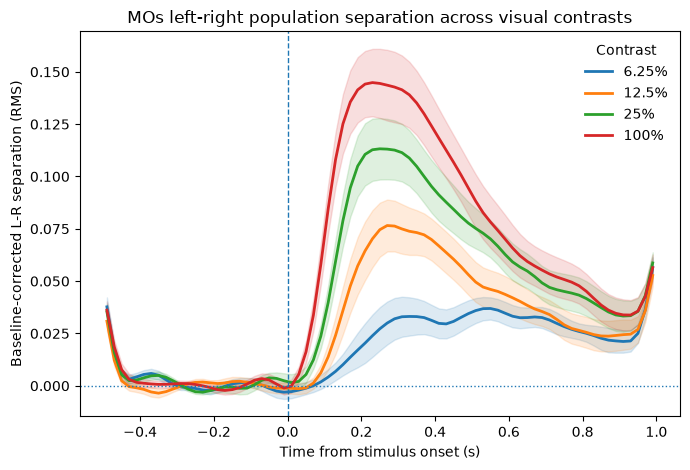

In [89]:
fig, ax = plt.subplots(
    figsize=(7.0, 4.8)
)


for contrast in ANALYSIS_CONTRASTS:

    plot_df = (
        separation_time_group_df.loc[
            separation_time_group_df[
                "contrast"
            ]
            .eq(
                contrast
            )
        ]
        .sort_values(
            "time_s"
        )
    )


    line = ax.plot(
        plot_df[
            "time_s"
        ],
        plot_df[
            "mean"
        ],
        linewidth=2.0,
        label=(
            f"{contrast:g}%"
        ),
    )[0]


    ax.fill_between(
        plot_df[
            "time_s"
        ],
        plot_df[
            "mean"
        ]
        -
        plot_df[
            "sem"
        ],
        plot_df[
            "mean"
        ]
        +
        plot_df[
            "sem"
        ],
        alpha=0.15,
        color=line.get_color(),
    )


ax.axvline(
    0,
    linestyle="--",
    linewidth=1.0,
)

ax.axhline(
    0,
    linestyle=":",
    linewidth=1.0,
)


ax.set_xlabel(
    "Time from stimulus onset (s)"
)

ax.set_ylabel(
    "Baseline-corrected L-R separation (RMS)"
)

ax.set_title(
    "MOs left-right population separation across visual contrasts"
)

ax.legend(
    title="Contrast",
    frameon=False,
)


plt.tight_layout()


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "04_cross_subject_separation_timecourse.png",
    dpi=300,
    bbox_inches="tight",
)


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "04_cross_subject_separation_timecourse.pdf",
    bbox_inches="tight",
)


plt.show()

In [90]:
# ============================================================
# 51. Build subject × contrast matrices
# ============================================================

excursion_wide = (
    subject_condition_summary_df
    .pivot(
        index="subject",
        columns="contrast",
        values="mean_evoked_excursion_rms",
    )
    .reindex(
        columns=ANALYSIS_CONTRASTS
    )
)


separation_wide = (
    subject_condition_summary_df
    .pivot(
        index="subject",
        columns="contrast",
        values="mean_evoked_separation_rms",
    )
    .reindex(
        columns=ANALYSIS_CONTRASTS
    )
)


print(
    "Excursion matrix:",
    excursion_wide.shape
)

print(
    "Separation matrix:",
    separation_wide.shape
)

print(
    "\nMissing excursion values:",
    int(
        excursion_wide
        .isna()
        .sum()
        .sum()
    )
)

print(
    "Missing separation values:",
    int(
        separation_wide
        .isna()
        .sum()
        .sum()
    )
)


display(
    excursion_wide.head()
)

Excursion matrix: (18, 4)
Separation matrix: (18, 4)

Missing excursion values: 0
Missing separation values: 0


contrast,6.25,12.50,25.00,100.00
subject,,,,
CSH-ZAD-024,0.234839,0.259272,0.249694,0.270351
CSHL049,0.098265,0.138589,0.152485,0.181852
CSHL058,0.080844,0.115032,0.151538,0.168860
CSHL060,0.170168,0.201438,0.228313,0.248426
DY-014,0.110187,0.135745,0.162497,0.167642


In [91]:
# ============================================================
# 52. Friedman repeated-measures tests
# ============================================================

from scipy.stats import friedmanchisquare

excursion_friedman = friedmanchisquare(
    *[
        excursion_wide[
            contrast
        ].to_numpy()
        for contrast
        in ANALYSIS_CONTRASTS
    ]
)


print(
    "Trajectory excursion:"
)

print(
    "Friedman chi-square =",
    excursion_friedman.statistic
)

print(
    "p =",
    excursion_friedman.pvalue
)

separation_friedman = friedmanchisquare(
    *[
        separation_wide[
            contrast
        ].to_numpy()
        for contrast
        in ANALYSIS_CONTRASTS
    ]
)


print(
    "\nLeft-right separation:"
)

print(
    "Friedman chi-square =",
    separation_friedman.statistic
)

print(
    "p =",
    separation_friedman.pvalue
)

Trajectory excursion:
Friedman chi-square = 46.19999999999999
p = 5.142461536240725e-10

Left-right separation:
Friedman chi-square = 38.46666666666664
p = 2.2512897209893257e-08


In [92]:
# ============================================================
# 53A. Contrast axis in log2 space
# ============================================================

contrast_log2 = np.log2(
    np.asarray(
        ANALYSIS_CONTRASTS,
        dtype=float,
    )
)


print(
    contrast_log2
)

[2.64385619 3.64385619 4.64385619 6.64385619]


In [93]:
# ============================================================
# Subject-level contrast-response slopes
# ============================================================

excursion_slope_rows = []


for subject, row in (
    excursion_wide.iterrows()
):

    y = (
        row[
            ANALYSIS_CONTRASTS
        ]
        .to_numpy(
            dtype=float
        )
    )


    slope = np.polyfit(
        contrast_log2,
        y,
        deg=1,
    )[0]


    excursion_slope_rows.append(
        {
            "subject":
                subject,

            "slope":
                slope,
        }
    )


excursion_slopes_df = pd.DataFrame(
    excursion_slope_rows
)


display(
    excursion_slopes_df
)

separation_slope_rows = []


for subject, row in (
    separation_wide.iterrows()
):

    y = (
        row[
            ANALYSIS_CONTRASTS
        ]
        .to_numpy(
            dtype=float
        )
    )


    slope = np.polyfit(
        contrast_log2,
        y,
        deg=1,
    )[0]


    separation_slope_rows.append(
        {
            "subject":
                subject,

            "slope":
                slope,
        }
    )


separation_slopes_df = pd.DataFrame(
    separation_slope_rows
)

,subject,slope
0,CSH-ZAD-024,0.007462
1,CSHL049,0.019587
2,CSHL058,0.021722
3,CSHL060,0.019105
4,DY-014,0.014078
5,KS023,0.021829
6,KS046,0.020495
7,NR-0027,0.011974
8,NYU-30,0.008794
9,SWC-038,0.035391


In [94]:
from scipy.stats import wilcoxon

excursion_slope_test = wilcoxon(
    excursion_slopes_df[
        "slope"
    ],
    alternative="greater",
)


print(
    "Excursion slope:"
)

print(
    "Median slope =",
    excursion_slopes_df[
        "slope"
    ].median()
)

print(
    "Positive subjects =",
    int(
        (
            excursion_slopes_df[
                "slope"
            ]
            > 0
        ).sum()
    ),
    "/",
    len(
        excursion_slopes_df
    ),
)

print(
    "Wilcoxon p =",
    excursion_slope_test.pvalue
)

separation_slope_test = wilcoxon(
    separation_slopes_df[
        "slope"
    ],
    alternative="greater",
)


print(
    "\nSeparation slope:"
)

print(
    "Median slope =",
    separation_slopes_df[
        "slope"
    ].median()
)

print(
    "Positive subjects =",
    int(
        (
            separation_slopes_df[
                "slope"
            ]
            > 0
        ).sum()
    ),
    "/",
    len(
        separation_slopes_df
    ),
)

print(
    "Wilcoxon p =",
    separation_slope_test.pvalue
)

Excursion slope:
Median slope = 0.015811554661818918
Positive subjects = 18 / 18
Wilcoxon p = 3.814697265625e-06

Separation slope:
Median slope = 0.015711485993649285
Positive subjects = 17 / 18
Wilcoxon p = 7.62939453125e-06


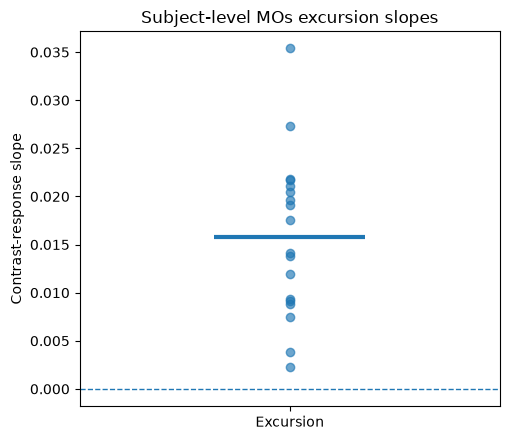

In [95]:
# ============================================================
# 55. Subject-level contrast-response slopes
# ============================================================

fig, ax = plt.subplots(
    figsize=(5.2, 4.5)
)


x_positions = np.zeros(
    len(
        excursion_slopes_df
    )
)


ax.scatter(
    x_positions,
    excursion_slopes_df[
        "slope"
    ],
    alpha=0.65,
)


ax.hlines(
    excursion_slopes_df[
        "slope"
    ].median(),
    xmin=-0.18,
    xmax=0.18,
    linewidth=3,
)


ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)


ax.set_xlim(
    -0.5,
    0.5,
)

ax.set_xticks(
    [0]
)

ax.set_xticklabels(
    [
        "Excursion"
    ]
)

ax.set_ylabel(
    "Contrast-response slope"
)

ax.set_title(
    "Subject-level MOs excursion slopes"
)


plt.tight_layout()
plt.show()

In [96]:
# ============================================================
# 56. Kendall's W effect size for Friedman tests
# ============================================================

n_subjects = excursion_wide.shape[0]
n_contrasts = excursion_wide.shape[1]


excursion_kendall_w = (
    excursion_friedman.statistic
    /
    (
        n_subjects
        *
        (n_contrasts - 1)
    )
)


separation_kendall_w = (
    separation_friedman.statistic
    /
    (
        n_subjects
        *
        (n_contrasts - 1)
    )
)


print(
    "Excursion Kendall's W =",
    excursion_kendall_w
)

print(
    "Separation Kendall's W =",
    separation_kendall_w
)

Excursion Kendall's W = 0.8555555555555553
Separation Kendall's W = 0.7123456790123451


In [97]:
#magnitude
magnitude_statistics_df = pd.DataFrame(
    [
        {
            "metric": "excursion",
            "friedman_chi2": excursion_friedman.statistic,
            "friedman_p": excursion_friedman.pvalue,
            "kendall_w": excursion_kendall_w,
            "median_slope": excursion_slopes_df["slope"].median(),
            "n_positive_slopes": (
                excursion_slopes_df["slope"] > 0
            ).sum(),
            "n_subjects": len(excursion_slopes_df),
            "slope_wilcoxon_p": excursion_slope_test.pvalue,
        },
        {
            "metric": "separation",
            "friedman_chi2": separation_friedman.statistic,
            "friedman_p": separation_friedman.pvalue,
            "kendall_w": separation_kendall_w,
            "median_slope": separation_slopes_df["slope"].median(),
            "n_positive_slopes": (
                separation_slopes_df["slope"] > 0
            ).sum(),
            "n_subjects": len(separation_slopes_df),
            "slope_wilcoxon_p": separation_slope_test.pvalue,
        },
    ]
)


display(
    magnitude_statistics_df
)


magnitude_statistics_df.to_csv(
    TABLE_DIR
    /
    "magnitude_statistics.csv",
    index=False,
)

,metric,friedman_chi2,friedman_p,kendall_w,median_slope,n_positive_slopes,n_subjects,slope_wilcoxon_p
0,excursion,46.200000,5.142462e-10,0.855556,0.015812,18,18,0.000004
1,separation,38.466667,2.251290e-08,0.712346,0.015711,17,18,0.000008


In [98]:
# ============================================================
# 57A. Timing / onset analysis configuration
# ============================================================

ONSET_START_S = 0.0
ONSET_END_S = 0.8

ONSET_N_PERMUTATIONS = 1000

# Require at least 3 consecutive significant 20-ms bins
ONSET_MIN_CONSECUTIVE_BINS = 3

ONSET_ALPHA = 0.05

ONSET_RANDOM_SEED = 20260812

In [99]:
# ============================================================
# 57B. Rebuild unsmoothed stimulus-aligned firing rates
# ============================================================

def rebuild_unsmoothed_firing_rates(
    selected_spike_times,
    valid_trials_df,
):

    n_trials = len(
        valid_trials_df
    )

    n_units = len(
        selected_spike_times
    )


    n_time_bins = int(
        round(
            (
                TIME_END_S
                -
                TIME_START_S
            )
            /
            BIN_SIZE_S
        )
    )


    time_bin_edges_s = np.linspace(
        TIME_START_S,
        TIME_END_S,
        n_time_bins + 1,
    )


    time_bin_centers_s = (
        time_bin_edges_s[:-1]
        +
        time_bin_edges_s[1:]
    ) / 2


    alignment_times = (
        pd.to_numeric(
            valid_trials_df[
                "gabor_stimulus_onset_time"
            ],
            errors="coerce",
        )
        .to_numpy(
            dtype=float
        )
    )


    spike_counts = np.zeros(
        (
            n_trials,
            n_units,
            n_time_bins,
        ),
        dtype=np.uint16,
    )


    for trial_index, alignment_time in enumerate(
        alignment_times
    ):

        absolute_edges = (
            alignment_time
            +
            time_bin_edges_s
        )


        for unit_index, spike_times in enumerate(
            selected_spike_times
        ):

            spike_counts[
                trial_index,
                unit_index,
                :
            ] = np.histogram(
                spike_times,
                bins=absolute_edges,
            )[0]


    firing_rates_hz = (
        spike_counts.astype(
            np.float32
        )
        /
        BIN_SIZE_S
    )


    return {
        "spike_counts":
            spike_counts,

        "firing_rates_hz":
            firing_rates_hz,

        "time_bin_edges_s":
            time_bin_edges_s,

        "time_bin_centers_s":
            time_bin_centers_s,
    }

In [100]:
# ============================================================
# 57C. Label-independent normalization for onset analysis
# ============================================================

def normalize_firing_rates_for_onset(
    firing_rates_hz,
    valid_trials_df,
    time_bin_centers_s,
):

    contrast_values = (
        pd.to_numeric(
            valid_trials_df[
                "gabor_stimulus_contrast"
            ],
            errors="coerce",
        )
        .to_numpy(
            dtype=float
        )
    )


    baseline_mask = (
        (
            time_bin_centers_s
            >= BASELINE_START_S
        )
        &
        (
            time_bin_centers_s
            < BASELINE_END_S
        )
    )


    # --------------------------------------------------------
    # 1. Common baseline, pooled across all valid trials
    # --------------------------------------------------------

    baseline_mean_hz = (
        firing_rates_hz[
            :,
            :,
            baseline_mask,
        ]
        .mean(
            axis=(0, 2)
        )
    )


    # --------------------------------------------------------
    # 2. Contrast-only condition means
    #
    # IMPORTANT:
    # left/right are pooled together
    # --------------------------------------------------------

    contrast_mean_rates = []


    for contrast in ANALYSIS_CONTRASTS:

        trial_mask = np.isclose(
            contrast_values,
            contrast,
        )


        contrast_mean = (
            firing_rates_hz[
                trial_mask,
                :,
                :
            ]
            .mean(
                axis=0
            )
        )


        contrast_mean_rates.append(
            contrast_mean
        )


    contrast_stack_hz = np.stack(
        contrast_mean_rates,
        axis=0,
    )


    # --------------------------------------------------------
    # 3. Unit-specific soft scale
    #
    # contrast × unit × time
    # --------------------------------------------------------

    unit_rate_range_hz = (
        contrast_stack_hz.max(
            axis=(0, 2)
        )
        -
        contrast_stack_hz.min(
            axis=(0, 2)
        )
    )


    soft_scale_hz = (
        unit_rate_range_hz
        +
        SOFT_NORMALIZATION_HZ
    )


    # --------------------------------------------------------
    # 4. Normalize EVERY individual trial
    # --------------------------------------------------------

    normalized_trial_rates = (
        (
            firing_rates_hz
            -
            baseline_mean_hz[
                None,
                :,
                None,
            ]
        )
        /
        soft_scale_hz[
            None,
            :,
            None,
        ]
    )


    return {
        "normalized_trial_rates":
            normalized_trial_rates,

        "baseline_mean_hz":
            baseline_mean_hz,

        "soft_scale_hz":
            soft_scale_hz,

        "baseline_mask":
            baseline_mask,
    }

In [101]:
# ============================================================
# 57D. Stratified shuffle of stimulus-side labels (within block)
# ============================================================

def shuffle_stimulus_side_within_block(
    stimulus_sides,
    probability_left_values,
    rng,
):

    shuffled_sides = (
        stimulus_sides.copy()
    )


    unique_blocks = np.unique(
        probability_left_values[
            ~pd.isna(
                probability_left_values
            )
        ]
    )


    for block_value in unique_blocks:

        block_indices = np.where(
            np.isclose(
                probability_left_values,
                block_value,
            )
        )[0]


        shuffled_sides[
            block_indices
        ] = (
            rng.permutation(
                stimulus_sides[
                    block_indices
                ]
            )
        )


    return shuffled_sides

In [102]:
# ============================================================
# 57E. Compute left-right RMS separation
# ============================================================

def compute_left_right_rms_separation(
    normalized_trial_rates,
    stimulus_sides,
):

    left_mask = (
        stimulus_sides
        == "left"
    )

    right_mask = (
        stimulus_sides
        == "right"
    )


    if left_mask.sum() == 0:

        raise ValueError(
            "No left trials."
        )


    if right_mask.sum() == 0:

        raise ValueError(
            "No right trials."
        )


    left_mean = (
        normalized_trial_rates[
            left_mask,
            :,
            :
        ]
        .mean(
            axis=0
        )
    )


    right_mean = (
        normalized_trial_rates[
            right_mask,
            :,
            :
        ]
        .mean(
            axis=0
        )
    )


    difference = (
        left_mean
        -
        right_mean
    )


    rms_separation = np.sqrt(
        np.mean(
            difference ** 2,
            axis=0,
        )
    )


    return rms_separation

In [103]:
# ============================================================
# 57F. Permutation-based onset threshold for one contrast
# ============================================================

def permutation_onset_for_one_contrast(
    normalized_trial_rates,
    valid_trials_df,
    time_bin_centers_s,
    contrast,
    n_permutations=ONSET_N_PERMUTATIONS,
    alpha=ONSET_ALPHA,
    min_consecutive_bins=ONSET_MIN_CONSECUTIVE_BINS,
    random_seed=ONSET_RANDOM_SEED,
):

    rng = np.random.default_rng(
        random_seed
    )


    contrast_values = (
        pd.to_numeric(
            valid_trials_df[
                "gabor_stimulus_contrast"
            ],
            errors="coerce",
        )
        .to_numpy(
            dtype=float
        )
    )


    stimulus_sides_all = (
        valid_trials_df[
            "gabor_stimulus_side"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .to_numpy()
    )


    probability_left_all = (
        pd.to_numeric(
            valid_trials_df[
                "probability_left"
            ],
            errors="coerce",
        )
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Select one contrast
    # --------------------------------------------------------

    contrast_mask = np.isclose(
        contrast_values,
        contrast,
    )


    contrast_rates = (
        normalized_trial_rates[
            contrast_mask,
            :,
            :
        ]
    )


    contrast_sides = (
        stimulus_sides_all[
            contrast_mask
        ]
    )


    contrast_probability_left = (
        probability_left_all[
            contrast_mask
        ]
    )


    n_left_trials = int(
        (
            contrast_sides
            == "left"
        ).sum()
    )


    n_right_trials = int(
        (
            contrast_sides
            == "right"
        ).sum()
    )


    # --------------------------------------------------------
    # Real separation
    # --------------------------------------------------------

    real_separation = (
        compute_left_right_rms_separation(
            contrast_rates,
            contrast_sides,
        )
    )


    onset_window_mask = (
        (
            time_bin_centers_s
            >= ONSET_START_S
        )
        &
        (
            time_bin_centers_s
            <= ONSET_END_S
        )
    )


    # --------------------------------------------------------
    # Null distribution of maximum separation
    # --------------------------------------------------------

    null_max_separation = np.zeros(
        n_permutations,
        dtype=float,
    )


    for permutation_index in range(
        n_permutations
    ):

        shuffled_sides = (
            shuffle_stimulus_side_within_block(
                stimulus_sides=
                    contrast_sides,

                probability_left_values=
                    contrast_probability_left,

                rng=
                    rng,
            )
        )


        shuffled_separation = (
            compute_left_right_rms_separation(
                contrast_rates,
                shuffled_sides,
            )
        )


        null_max_separation[
            permutation_index
        ] = (
            shuffled_separation[
                onset_window_mask
            ]
            .max()
        )


    # --------------------------------------------------------
    # Family-wise corrected threshold
    # --------------------------------------------------------

    threshold = float(
        np.quantile(
            null_max_separation,
            1.0 - alpha,
        )
    )


    # --------------------------------------------------------
    # Above-threshold bins
    # --------------------------------------------------------

    significant_mask = (
        real_separation
        >
        threshold
    )


    # Only search for onset after stimulus onset
    significant_onset_mask = (
        significant_mask
        &
        onset_window_mask
    )


    # --------------------------------------------------------
    # Require consecutive significant bins
    # --------------------------------------------------------

    onset_index = None


    candidate_indices = np.where(
        significant_onset_mask
    )[0]


    for index in candidate_indices:

        end_index = (
            index
            +
            min_consecutive_bins
        )


        if (
            end_index
            >
            len(
                significant_onset_mask
            )
        ):

            continue


        if np.all(
            significant_onset_mask[
                index:end_index
            ]
        ):

            onset_index = int(
                index
            )

            break


    if onset_index is None:

        onset_time_s = np.nan

    else:

        onset_time_s = float(
            time_bin_centers_s[
                onset_index
            ]
        )


    return {
        "contrast":
            contrast,

        "n_left_trials":
            n_left_trials,

        "n_right_trials":
            n_right_trials,

        "real_separation":
            real_separation,

        "null_max_separation":
            null_max_separation,

        "threshold":
            threshold,

        "significant_mask":
            significant_mask,

        "onset_time_s":
            onset_time_s,
    }

In [104]:
# ============================================================
# 57G. Run onset analysis for one session
# ============================================================

def run_onset_analysis_for_session(
    session_id,
):

    # --------------------------------------------------------
    # Load local extraction
    # --------------------------------------------------------

    extracted_data = (
        load_extraction_checkpoint(
            session_id
        )
    )


    valid_trials_df = (
        extracted_data[
            "valid_trials_df"
        ]
    )


    selected_spike_times = (
        extracted_data[
            "selected_spike_times"
        ]
    )


    # --------------------------------------------------------
    # Rebuild UNSMOOTHED firing rates
    # --------------------------------------------------------

    binned = (
        rebuild_unsmoothed_firing_rates(
            selected_spike_times,
            valid_trials_df,
        )
    )


    firing_rates_hz = (
        binned[
            "firing_rates_hz"
        ]
    )


    time_bin_centers_s = (
        binned[
            "time_bin_centers_s"
        ]
    )


    # --------------------------------------------------------
    # Label-independent normalization
    # --------------------------------------------------------

    normalization = (
        normalize_firing_rates_for_onset(
            firing_rates_hz,
            valid_trials_df,
            time_bin_centers_s,
        )
    )


    normalized_trial_rates = (
        normalization[
            "normalized_trial_rates"
        ]
    )


    # --------------------------------------------------------
    # Run four contrasts
    # --------------------------------------------------------

    onset_results = {}


    for contrast in ANALYSIS_CONTRASTS:

        print(
            f"Running {contrast:g}% contrast ..."
        )


        onset_results[
            contrast
        ] = (
            permutation_onset_for_one_contrast(
                normalized_trial_rates=
                    normalized_trial_rates,

                valid_trials_df=
                    valid_trials_df,

                time_bin_centers_s=
                    time_bin_centers_s,

                contrast=
                    contrast,
            )
        )


        print(
            "  threshold =",
            onset_results[
                contrast
            ][
                "threshold"
            ]
        )

        print(
            "  onset =",
            onset_results[
                contrast
            ][
                "onset_time_s"
            ],
            "s"
        )


    return {
        "valid_trials_df":
            valid_trials_df,

        "time_bin_centers_s":
            time_bin_centers_s,

        "normalized_trial_rates":
            normalized_trial_rates,

        "onset_results":
            onset_results,
    }

In [105]:
# ============================================================
# 57H. Prototype timing analysis
# ============================================================

prototype_onset_analysis = (
    run_onset_analysis_for_session(
        PROTOTYPE_SESSION
    )
)

Running 6.25% contrast ...
  threshold = 0.20397070646286009
  onset = nan s
Running 12.5% contrast ...
  threshold = 0.2400518201291561
  onset = nan s
Running 25% contrast ...
  threshold = 0.20852117910981177
  onset = 0.19000000000000006 s
Running 100% contrast ...
  threshold = 0.24316978082060814
  onset = 0.15000000000000002 s


In [106]:
# ============================================================
# 57I. Prototype onset summary
# ============================================================

prototype_onset_rows = []


for contrast in ANALYSIS_CONTRASTS:

    result = (
        prototype_onset_analysis[
            "onset_results"
        ][
            contrast
        ]
    )


    prototype_onset_rows.append(
        {
            "contrast":
                contrast,

            "n_left_trials":
                result[
                    "n_left_trials"
                ],

            "n_right_trials":
                result[
                    "n_right_trials"
                ],

            "threshold":
                result[
                    "threshold"
                ],

            "onset_time_s":
                result[
                    "onset_time_s"
                ],
        }
    )


prototype_onset_df = pd.DataFrame(
    prototype_onset_rows
)


display(
    prototype_onset_df
)

,contrast,n_left_trials,n_right_trials,threshold,onset_time_s
0,6.25,54,60,0.203971,NaN
1,12.50,54,41,0.240052,NaN
2,25.00,76,66,0.208521,0.19
3,100.00,70,57,0.243170,0.15


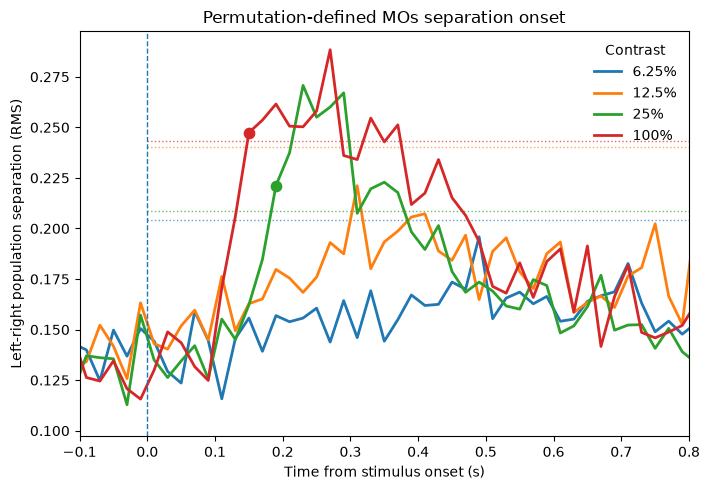

In [107]:
# ============================================================
# 57J. Plot prototype permutation-defined onset
# ============================================================

time_s = (
    prototype_onset_analysis[
        "time_bin_centers_s"
    ]
)


fig, ax = plt.subplots(
    figsize=(7.2, 5.0)
)


for contrast in ANALYSIS_CONTRASTS:

    result = (
        prototype_onset_analysis[
            "onset_results"
        ][
            contrast
        ]
    )


    line = ax.plot(
        time_s,
        result[
            "real_separation"
        ],
        linewidth=2.0,
        label=(
            f"{contrast:g}%"
        ),
    )[0]


    # permutation threshold
    ax.hlines(
        result[
            "threshold"
        ],
        xmin=ONSET_START_S,
        xmax=ONSET_END_S,
        linestyle=":",
        linewidth=1.0,
        color=line.get_color(),
        alpha=0.7,
    )


    onset_time = (
        result[
            "onset_time_s"
        ]
    )


    if np.isfinite(
        onset_time
    ):

        onset_index = np.argmin(
            np.abs(
                time_s
                -
                onset_time
            )
        )


        ax.scatter(
            onset_time,
            result[
                "real_separation"
            ][
                onset_index
            ],
            s=55,
            zorder=5,
            color=line.get_color(),
        )


ax.axvline(
    0,
    linestyle="--",
    linewidth=1.0,
)


ax.set_xlim(
    -0.1,
    0.8,
)


ax.set_xlabel(
    "Time from stimulus onset (s)"
)

ax.set_ylabel(
    "Left-right population separation (RMS)"
)

ax.set_title(
    "Permutation-defined MOs separation onset"
)


ax.legend(
    title="Contrast",
    frameon=False,
)


plt.tight_layout()
plt.show()

In [108]:
# ============================================================
# 58A. Freeze onset-analysis parameters
# ============================================================

ONSET_N_PERMUTATIONS = 2000

ONSET_START_S = 0.0
ONSET_END_S = 0.8

ONSET_ALPHA = 0.05

ONSET_MIN_CONSECUTIVE_BINS = 3

ONSET_RANDOM_SEED = 20260812

In [109]:
# ============================================================
# 58B. Onset output paths
# ============================================================

def get_onset_paths(
    session_id,
):

    session_paths = (
        get_session_paths(
            session_id
        )
    )


    onset_dir = (
        session_paths[
            "session_dir"
        ]
        /
        "onset"
    )


    onset_dir.mkdir(
        parents=True,
        exist_ok=True,
    )


    return {
        "onset_dir":
            onset_dir,

        "summary_path":
            onset_dir
            /
            "onset_summary.csv",

        "timecourse_path":
            onset_dir
            /
            "onset_timecourse.csv",

        "null_path":
            onset_dir
            /
            "null_max_separation.npz",

        "complete_marker":
            onset_dir
            /
            "ONSET_COMPLETE.txt",
    }

In [110]:
# ============================================================
# 58C. Deterministic permutation seed
# ============================================================

import hashlib


def make_onset_seed(
    session_id,
    contrast,
):

    text = (
        f"{ONSET_RANDOM_SEED}"
        f"|{session_id}"
        f"|{contrast}"
    )


    digest = hashlib.sha256(
        text.encode(
            "utf-8"
        )
    ).hexdigest()


    seed = int(
        digest[:8],
        16,
    )


    return seed

In [111]:
# ============================================================
# 58D. Fast permutation onset for one contrast
# ============================================================

def permutation_onset_for_one_contrast_fast(
    normalized_trial_rates,
    valid_trials_df,
    time_bin_centers_s,
    contrast,
    n_permutations=ONSET_N_PERMUTATIONS,
    alpha=ONSET_ALPHA,
    min_consecutive_bins=ONSET_MIN_CONSECUTIVE_BINS,
    random_seed=ONSET_RANDOM_SEED,
):

    rng = np.random.default_rng(
        random_seed
    )


    # --------------------------------------------------------
    # Trial metadata
    # --------------------------------------------------------

    contrast_values = (
        pd.to_numeric(
            valid_trials_df[
                "gabor_stimulus_contrast"
            ],
            errors="coerce",
        )
        .to_numpy(
            dtype=float
        )
    )


    stimulus_sides_all = (
        valid_trials_df[
            "gabor_stimulus_side"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .to_numpy()
    )


    probability_left_all = (
        pd.to_numeric(
            valid_trials_df[
                "probability_left"
            ],
            errors="coerce",
        )
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Select this contrast
    # --------------------------------------------------------

    contrast_mask = np.isclose(
        contrast_values,
        contrast,
    )


    contrast_rates = (
        normalized_trial_rates[
            contrast_mask,
            :,
            :
        ]
    )


    contrast_sides = (
        stimulus_sides_all[
            contrast_mask
        ]
    )


    contrast_probability_left = (
        probability_left_all[
            contrast_mask
        ]
    )


    n_trials = (
        contrast_rates.shape[0]
    )

    n_units = (
        contrast_rates.shape[1]
    )


    n_left_trials = int(
        (
            contrast_sides
            == "left"
        ).sum()
    )


    n_right_trials = int(
        (
            contrast_sides
            == "right"
        ).sum()
    )


    if (
        n_left_trials == 0
        or
        n_right_trials == 0
    ):

        raise ValueError(
            f"{contrast}% contrast has "
            f"insufficient left/right trials."
        )


    # ========================================================
    # Real separation
    # ========================================================

    real_separation = (
        compute_left_right_rms_separation(
            contrast_rates,
            contrast_sides,
        )
    )


    # --------------------------------------------------------
    # Onset window
    # --------------------------------------------------------

    onset_window_mask = (
        (
            time_bin_centers_s
            >= ONSET_START_S
        )
        &
        (
            time_bin_centers_s
            <= ONSET_END_S
        )
    )


    onset_time_centers = (
        time_bin_centers_s[
            onset_window_mask
        ]
    )


    contrast_rates_onset = (
        contrast_rates[
            :,
            :,
            onset_window_mask,
        ]
        .astype(
            np.float32,
            copy=False,
        )
    )


    n_onset_bins = (
        contrast_rates_onset.shape[2]
    )


    # ========================================================
    # Build permutation weight matrix
    #
    # one row = one shuffle
    #
    # fake-left  → +1/n_left
    # fake-right → -1/n_right
    #
    # weights @ neural_activity
    # directly gives:
    #
    # mean(fake-left) - mean(fake-right)
    # ========================================================

    permutation_weights = np.zeros(
        (
            n_permutations,
            n_trials,
        ),
        dtype=np.float32,
    )


    for permutation_index in range(
        n_permutations
    ):

        shuffled_sides = (
            shuffle_stimulus_side_within_block(
                stimulus_sides=
                    contrast_sides,

                probability_left_values=
                    contrast_probability_left,

                rng=
                    rng,
            )
        )


        fake_left = (
            shuffled_sides
            == "left"
        )

        fake_right = (
            shuffled_sides
            == "right"
        )


        fake_n_left = int(
            fake_left.sum()
        )

        fake_n_right = int(
            fake_right.sum()
        )


        permutation_weights[
            permutation_index,
            fake_left,
        ] = (
            1.0
            /
            fake_n_left
        )


        permutation_weights[
            permutation_index,
            fake_right,
        ] = (
            -1.0
            /
            fake_n_right
        )


    # ========================================================
    # Vectorized calculation
    # ========================================================

    flat_rates = (
        contrast_rates_onset
        .reshape(
            n_trials,
            -1,
        )
    )


    # shape:
    #
    # permutations × (units × time)
    null_difference_flat = (
        permutation_weights
        @
        flat_rates
    )


    null_difference = (
        null_difference_flat
        .reshape(
            n_permutations,
            n_units,
            n_onset_bins,
        )
    )


    # RMS across units
    #
    # shape:
    # permutations × time
    null_separation = np.sqrt(
        np.mean(
            null_difference ** 2,
            axis=1,
        )
    )


    # --------------------------------------------------------
    # Max statistic across the complete 0–800 ms window
    # --------------------------------------------------------

    null_max_separation = (
        null_separation
        .max(
            axis=1
        )
    )


    threshold = float(
        np.quantile(
            null_max_separation,
            1.0 - alpha,
        )
    )


    # ========================================================
    # Real significant bins
    # ========================================================

    significant_mask = (
        real_separation
        >
        threshold
    )


    significant_onset_mask = (
        significant_mask
        &
        onset_window_mask
    )


    # ========================================================
    # Find first run of >= 3 consecutive bins
    # ========================================================

    onset_index = None


    candidate_indices = np.where(
        significant_onset_mask
    )[0]


    for index in candidate_indices:

        end_index = (
            index
            +
            min_consecutive_bins
        )


        if (
            end_index
            >
            len(
                significant_onset_mask
            )
        ):

            continue


        if np.all(
            significant_onset_mask[
                index:end_index
            ]
        ):

            onset_index = int(
                index
            )

            break


    if onset_index is None:

        onset_center_s = np.nan
        onset_latency_s = np.nan
        onset_detected = False

    else:

        onset_center_s = float(
            time_bin_centers_s[
                onset_index
            ]
        )


        # More conservative formal timestamp:
        # use the RIGHT EDGE of the 20-ms bin.
        onset_latency_s = (
            onset_center_s
            +
            BIN_SIZE_S / 2
        )


        onset_detected = True


    # ========================================================
    # Peak separation inside analysis window
    # ========================================================

    real_onset_window = (
        real_separation[
            onset_window_mask
        ]
    )


    peak_local_index = int(
        np.argmax(
            real_onset_window
        )
    )


    peak_separation_rms = float(
        real_onset_window[
            peak_local_index
        ]
    )


    peak_time_center_s = float(
        onset_time_centers[
            peak_local_index
        ]
    )


    return {
        "contrast":
            contrast,

        "n_left_trials":
            n_left_trials,

        "n_right_trials":
            n_right_trials,

        "threshold":
            threshold,

        "onset_detected":
            onset_detected,

        # useful for comparison with prototype plot
        "onset_center_s":
            onset_center_s,

        # use this later as formal latency
        "onset_latency_s":
            onset_latency_s,

        "peak_separation_rms":
            peak_separation_rms,

        "peak_time_center_s":
            peak_time_center_s,

        "real_separation":
            real_separation,

        "significant_mask":
            significant_mask,

        "null_max_separation":
            null_max_separation,
    }

In [112]:
# ============================================================
# 58E. Analyze and save one onset session
# ============================================================

def analyze_and_save_onset_session(
    session_row,
):

    subject = str(
        session_row[
            "subject"
        ]
    )

    session = str(
        session_row[
            "session"
        ]
    )


    onset_paths = (
        get_onset_paths(
            session
        )
    )


    # --------------------------------------------------------
    # Resume support
    # --------------------------------------------------------

    if (
        onset_paths[
            "complete_marker"
        ]
        .exists()
    ):

        print(
            f"SKIP {session}: "
            "onset analysis already complete."
        )

        return "already_complete"


    print(
        f"\nTiming analysis: "
        f"{subject} | {session}"
    )


    # ========================================================
    # Load LOCAL checkpoint
    # ========================================================

    extracted_data = (
        load_extraction_checkpoint(
            session
        )
    )


    valid_trials_df = (
        extracted_data[
            "valid_trials_df"
        ]
    )


    selected_units_df = (
        extracted_data[
            "selected_units_df"
        ]
    )


    selected_spike_times = (
        extracted_data[
            "selected_spike_times"
        ]
    )


    # ========================================================
    # Unsmoothed 20-ms firing rates
    # ========================================================

    binned = (
        rebuild_unsmoothed_firing_rates(
            selected_spike_times,
            valid_trials_df,
        )
    )


    firing_rates_hz = (
        binned[
            "firing_rates_hz"
        ]
    )


    time_bin_centers_s = (
        binned[
            "time_bin_centers_s"
        ]
    )


    # ========================================================
    # Label-independent normalization
    # ========================================================

    normalization = (
        normalize_firing_rates_for_onset(
            firing_rates_hz,
            valid_trials_df,
            time_bin_centers_s,
        )
    )


    normalized_trial_rates = (
        normalization[
            "normalized_trial_rates"
        ]
    )


    # ========================================================
    # Four contrasts
    # ========================================================

    summary_rows = []
    timecourse_rows = []

    null_payload = {}


    for contrast in ANALYSIS_CONTRASTS:

        print(
            f"  {contrast:g}% ..."
        )


        seed = (
            make_onset_seed(
                session,
                contrast,
            )
        )


        result = (
            permutation_onset_for_one_contrast_fast(
                normalized_trial_rates=
                    normalized_trial_rates,

                valid_trials_df=
                    valid_trials_df,

                time_bin_centers_s=
                    time_bin_centers_s,

                contrast=
                    contrast,

                n_permutations=
                    ONSET_N_PERMUTATIONS,

                random_seed=
                    seed,
            )
        )


        # ----------------------------------------------------
        # Summary row
        # ----------------------------------------------------

        summary_rows.append(
            {
                "subject":
                    subject,

                "session":
                    session,

                "contrast":
                    contrast,

                "n_good_units":
                    len(
                        selected_units_df
                    ),

                "n_left_trials":
                    result[
                        "n_left_trials"
                    ],

                "n_right_trials":
                    result[
                        "n_right_trials"
                    ],

                "threshold":
                    result[
                        "threshold"
                    ],

                "onset_detected":
                    result[
                        "onset_detected"
                    ],

                "onset_center_s":
                    result[
                        "onset_center_s"
                    ],

                "onset_latency_s":
                    result[
                        "onset_latency_s"
                    ],

                "peak_separation_rms":
                    result[
                        "peak_separation_rms"
                    ],

                "peak_time_center_s":
                    result[
                        "peak_time_center_s"
                    ],
            }
        )


        # ----------------------------------------------------
        # Full real timecourse
        # ----------------------------------------------------

        for time_index, time_s in enumerate(
            time_bin_centers_s
        ):

            timecourse_rows.append(
                {
                    "subject":
                        subject,

                    "session":
                        session,

                    "contrast":
                        contrast,

                    "time_s":
                        float(
                            time_s
                        ),

                    "separation_rms":
                        float(
                            result[
                                "real_separation"
                            ][
                                time_index
                            ]
                        ),

                    "threshold":
                        result[
                            "threshold"
                        ],

                    "above_threshold":
                        bool(
                            result[
                                "significant_mask"
                            ][
                                time_index
                            ]
                        ),
                }
            )


        # ----------------------------------------------------
        # Save null distribution
        # ----------------------------------------------------

        contrast_label = (
            str(
                contrast
            )
            .replace(
                ".",
                "p",
            )
        )


        null_payload[
            f"contrast_{contrast_label}"
        ] = (
            result[
                "null_max_separation"
            ]
        )


        print(
            "     detected =",
            result[
                "onset_detected"
            ],
            "| onset =",
            result[
                "onset_latency_s"
            ],
            "s",
        )


    # ========================================================
    # Save outputs
    # ========================================================

    onset_summary_df = (
        pd.DataFrame(
            summary_rows
        )
    )


    onset_timecourse_df = (
        pd.DataFrame(
            timecourse_rows
        )
    )


    onset_summary_df.to_csv(
        onset_paths[
            "summary_path"
        ],
        index=False,
    )


    onset_timecourse_df.to_csv(
        onset_paths[
            "timecourse_path"
        ],
        index=False,
    )


    np.savez_compressed(
        onset_paths[
            "null_path"
        ],
        **null_payload,
    )


    # Marker written LAST
    onset_paths[
        "complete_marker"
    ].write_text(
        "complete\n",
        encoding="utf-8",
    )


    print(
        f"  COMPLETE: {session}"
    )


    return "completed"

In [113]:
# ============================================================
# 58F. Run onset batch across all eligible MOs sessions
# ============================================================

ONSET_BATCH_LOG_PATH = (
    TABLE_DIR
    /
    "onset_batch_log.csv"
)


onset_batch_log_rows = []


for _, session_row in tqdm(
    batch_sessions_df.iterrows(),
    total=len(
        batch_sessions_df
    ),
    desc="MOs onset batch",
):

    subject = str(
        session_row[
            "subject"
        ]
    )

    session = str(
        session_row[
            "session"
        ]
    )


    try:

        status = (
            analyze_and_save_onset_session(
                session_row
            )
        )


        onset_batch_log_rows.append(
            {
                "subject":
                    subject,

                "session":
                    session,

                "status":
                    status,

                "error_type":
                    pd.NA,

                "error_message":
                    pd.NA,
            }
        )


    except Exception as error:

        print(
            f"\nFAILED: {session}"
        )

        print(
            type(error).__name__,
            ":",
            str(error),
        )


        onset_batch_log_rows.append(
            {
                "subject":
                    subject,

                "session":
                    session,

                "status":
                    "failed",

                "error_type":
                    type(
                        error
                    ).__name__,

                "error_message":
                    str(
                        error
                    ),
            }
        )


    # --------------------------------------------------------
    # Save log after every session
    # --------------------------------------------------------

    pd.DataFrame(
        onset_batch_log_rows
    ).to_csv(
        ONSET_BATCH_LOG_PATH,
        index=False,
    )


    gc.collect()

MOs onset batch:   0%|          | 0/22 [00:00<?, ?it/s]


Timing analysis: SWC-038 | 4d8c7767-981c-4347-8e5e-5d5fffe38534
  6.25% ...
     detected = False | onset = nan s
  12.5% ...
     detected = False | onset = nan s
  25% ...
     detected = True | onset = 0.20000000000000007 s
  100% ...
     detected = True | onset = 0.16000000000000003 s
  COMPLETE: 4d8c7767-981c-4347-8e5e-5d5fffe38534


MOs onset batch:   5%|▍         | 1/22 [00:13<04:36, 13.18s/it]


Timing analysis: ZM-2240 | d33baf74-263c-4b37-a0d0-b79dcb80a764
  6.25% ...
     detected = False | onset = nan s
  12.5% ...
     detected = False | onset = nan s
  25% ...
     detected = True | onset = 0.18000000000000005 s
  100% ...


MOs onset batch:   9%|▉         | 2/22 [00:18<02:50,  8.52s/it]

     detected = True | onset = 0.11999999999999998 s
  COMPLETE: d33baf74-263c-4b37-a0d0-b79dcb80a764

Timing analysis: CSHL058 | fb70ebf7-8175-42b0-9b7a-7c6e8612226e
  6.25% ...
     detected = False | onset = nan s
  12.5% ...
     detected = True | onset = 0.22000000000000003 s
  25% ...
     detected = True | onset = 0.16000000000000003 s
  100% ...


... (36 outputs left out)

MOs onset batch:  95%|█████████▌| 21/22 [02:42<00:04,  4.76s/it]

     detected = True | onset = 0.09999999999999996 s
  COMPLETE: a4000c2f-fa75-4b3e-8f06-a7cf599b87ad

Timing analysis: ZM-1897 | dd4da095-4a99-4bf3-9727-f735077dba66
  6.25% ...
     detected = False | onset = nan s
  12.5% ...
     detected = False | onset = nan s
  25% ...
     detected = False | onset = nan s
  100% ...


MOs onset batch: 100%|██████████| 22/22 [02:43<00:00,  7.44s/it]

     detected = False | onset = nan s
  COMPLETE: dd4da095-4a99-4bf3-9727-f735077dba66


In [114]:
# ============================================================
# 58G. Batch status
# ============================================================

onset_batch_log_df = pd.read_csv(
    ONSET_BATCH_LOG_PATH
)


display(
    onset_batch_log_df
)


print(
    "\nStatus:"
)

display(
    onset_batch_log_df[
        "status"
    ]
    .value_counts(
        dropna=False
    )
)

,subject,session,status,error_type,error_message
0,SWC-038,4d8c7767-981c-4347-8e5e-5d5fffe38534,completed,NaN,NaN
1,ZM-2240,d33baf74-263c-4b37-a0d0-b79dcb80a764,completed,NaN,NaN
2,CSHL058,fb70ebf7-8175-42b0-9b7a-7c6e8612226e,completed,NaN,NaN
3,ZM-2241,ff4187b5-4176-4e39-8894-53a24b7cf36b,completed,NaN,NaN
4,NR-0027,0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde,completed,NaN,NaN
5,CSHL049,d2918f52-8280-43c0-924b-029b2317e62c,completed,NaN,NaN
6,ZFM-02370,6f6d2c8e-28be-49f4-ae4d-06be2d3148c1,completed,NaN,NaN
7,KS023,aad23144-0e52-4eac-80c5-c4ee2decb198,completed,NaN,NaN
8,CSH-ZAD-024,8207abc6-6b23-4762-92b4-82e05bed5143,completed,NaN,NaN
9,CSHL060,2e6e179c-fccc-4e8f-9448-ce5b6858a183,completed,NaN,NaN



Status:


status
completed    22
Name: count, dtype: int64

In [115]:
# ============================================================
# 58H. Aggregate onset results
# ============================================================

all_onset_summaries = []
all_onset_timecourses = []


for _, session_row in (
    batch_sessions_df.iterrows()
):

    session = str(
        session_row[
            "session"
        ]
    )


    onset_paths = (
        get_onset_paths(
            session
        )
    )


    if not (
        onset_paths[
            "complete_marker"
        ]
        .exists()
    ):

        continue


    all_onset_summaries.append(
        pd.read_csv(
            onset_paths[
                "summary_path"
            ]
        )
    )


    all_onset_timecourses.append(
        pd.read_csv(
            onset_paths[
                "timecourse_path"
            ]
        )
    )

cross_session_onset_df = (
    pd.concat(
        all_onset_summaries,
        ignore_index=True,
    )
)


cross_session_onset_timecourse_df = (
    pd.concat(
        all_onset_timecourses,
        ignore_index=True,
    )
)

cross_session_onset_df.to_csv(
    TABLE_DIR
    /
    "cross_session_onset_summary.csv",
    index=False,
)


cross_session_onset_timecourse_df.to_csv(
    TABLE_DIR
    /
    "cross_session_onset_timecourse.csv",
    index=False,
)

print(
    "Sessions:",
    cross_session_onset_df[
        "session"
    ].nunique()
)

print(
    "Subjects:",
    cross_session_onset_df[
        "subject"
    ].nunique()
)

print(
    "Rows:",
    len(
        cross_session_onset_df
    )
)


assert (
    len(
        cross_session_onset_df
    )
    ==
    22
    *
    len(
        ANALYSIS_CONTRASTS
    )
)


print(
    "Onset aggregation QC passed."
)

Sessions: 22
Subjects: 18
Rows: 88
Onset aggregation QC passed.


In [116]:
# ============================================================
# 58I. Detection summary by contrast
# ============================================================

onset_detection_summary_df = (
    cross_session_onset_df
    .groupby(
        "contrast",
        as_index=False,
    )
    .agg(
        n_sessions=(
            "session",
            "nunique",
        ),

        n_detected=(
            "onset_detected",
            "sum",
        ),

        median_onset_detected_s=(
            "onset_latency_s",
            "median",
        ),
    )
)


onset_detection_summary_df[
    "detection_fraction"
] = (
    onset_detection_summary_df[
        "n_detected"
    ]
    /
    onset_detection_summary_df[
        "n_sessions"
    ]
)


display(
    onset_detection_summary_df
)

,contrast,n_sessions,n_detected,median_onset_detected_s,detection_fraction
0,6.25,22,2,0.26,0.090909
1,12.50,22,7,0.16,0.318182
2,25.00,22,13,0.16,0.590909
3,100.00,22,16,0.12,0.727273


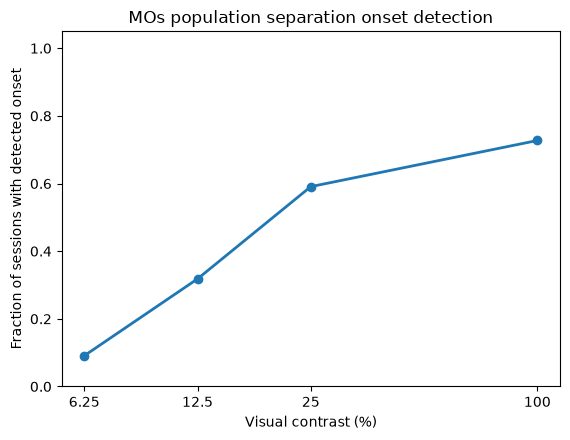

In [117]:
# ============================================================
# 58J. Plot onset detection fraction
# ============================================================

fig, ax = plt.subplots(
    figsize=(5.8, 4.5)
)


ax.plot(
    onset_detection_summary_df[
        "contrast"
    ],
    onset_detection_summary_df[
        "detection_fraction"
    ],
    marker="o",
    linewidth=2,
)


ax.set_xscale(
    "log",
    base=2,
)


ax.set_xticks(
    ANALYSIS_CONTRASTS
)


ax.set_xticklabels(
    [
        f"{contrast:g}"
        for contrast
        in ANALYSIS_CONTRASTS
    ]
)


ax.set_ylim(
    0,
    1.05,
)


ax.set_xlabel(
    "Visual contrast (%)"
)


ax.set_ylabel(
    "Fraction of sessions with detected onset"
)


ax.set_title(
    "MOs population separation onset detection"
)


plt.tight_layout()
plt.show()

In [118]:
# ============================================================
# 59A. Cumulative onset-detection curves
# ============================================================

ONSET_TIME_GRID_S = np.arange(
    0.0,
    ONSET_END_S + BIN_SIZE_S,
    BIN_SIZE_S,
)


cumulative_onset_rows = []


for contrast in ANALYSIS_CONTRASTS:

    contrast_df = (
        cross_session_onset_df.loc[
            cross_session_onset_df[
                "contrast"
            ].eq(
                contrast
            )
        ]
        .copy()
    )


    n_sessions = len(
        contrast_df
    )


    onset_times = (
        pd.to_numeric(
            contrast_df[
                "onset_latency_s"
            ],
            errors="coerce",
        )
        .to_numpy(
            dtype=float
        )
    )


    for time_s in ONSET_TIME_GRID_S:

        # NaN automatically evaluates False here:
        # a session with no detected onset does NOT count
        # as having reached onset by this time.
        n_reached = int(
            np.sum(
                onset_times
                <= time_s
            )
        )


        cumulative_onset_rows.append(
            {
                "contrast":
                    contrast,

                "time_s":
                    time_s,

                "n_sessions":
                    n_sessions,

                "n_onset_by_time":
                    n_reached,

                "fraction_onset_by_time":
                    n_reached
                    /
                    n_sessions,
            }
        )


cumulative_onset_df = pd.DataFrame(
    cumulative_onset_rows
)

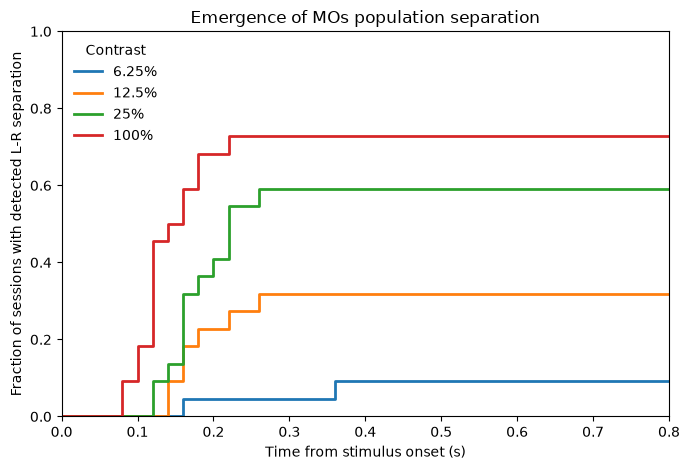

In [119]:
# ============================================================
# 59B. Plot cumulative onset curves
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.0, 4.8)
)


for contrast in ANALYSIS_CONTRASTS:

    plot_df = (
        cumulative_onset_df.loc[
            cumulative_onset_df[
                "contrast"
            ].eq(
                contrast
            )
        ]
        .sort_values(
            "time_s"
        )
    )


    ax.step(
        plot_df[
            "time_s"
        ],
        plot_df[
            "fraction_onset_by_time"
        ],
        where="post",
        linewidth=2.0,
        label=f"{contrast:g}%",
    )


ax.set_xlim(
    0,
    ONSET_END_S,
)

ax.set_ylim(
    0,
    1.0,
)


ax.set_xlabel(
    "Time from stimulus onset (s)"
)

ax.set_ylabel(
    "Fraction of sessions with detected L-R separation"
)

ax.set_title(
    "Emergence of MOs population separation"
)


ax.legend(
    title="Contrast",
    frameon=False,
)


plt.tight_layout()
plt.show()

In [120]:
# ============================================================
# 60A. Baseline-correct unsmoothed separation timecourses
# ============================================================

timing_session_df = (
    cross_session_onset_timecourse_df
    .copy()
)


timing_session_df["time_s"] = (
    pd.to_numeric(
        timing_session_df["time_s"],
        errors="coerce",
    )
)


timing_session_df["contrast"] = (
    pd.to_numeric(
        timing_session_df["contrast"],
        errors="coerce",
    )
)


timing_session_df["separation_rms"] = (
    pd.to_numeric(
        timing_session_df["separation_rms"],
        errors="coerce",
    )
)


# ------------------------------------------------------------
# Pre-stimulus baseline
# Same window used previously:
# -0.35 to -0.15 s
# ------------------------------------------------------------

baseline_timing_df = (
    timing_session_df.loc[
        (
            timing_session_df["time_s"]
            >= BASELINE_START_S
        )
        &
        (
            timing_session_df["time_s"]
            < BASELINE_END_S
        )
    ]
    .groupby(
        [
            "subject",
            "session",
            "contrast",
        ],
        as_index=False,
    )
    .agg(
        baseline_separation_rms=(
            "separation_rms",
            "mean",
        )
    )
)


timing_session_df = (
    timing_session_df
    .merge(
        baseline_timing_df,
        on=[
            "subject",
            "session",
            "contrast",
        ],
        how="left",
        validate="many_to_one",
    )
)


timing_session_df[
    "separation_bc_rms"
] = (
    timing_session_df[
        "separation_rms"
    ]
    -
    timing_session_df[
        "baseline_separation_rms"
    ]
)

In [121]:
print(
    "Rows:",
    len(timing_session_df)
)

print(
    "Missing baseline:",
    timing_session_df[
        "baseline_separation_rms"
    ]
    .isna()
    .sum()
)

Rows: 6600
Missing baseline: 0


In [122]:
# ============================================================
# 60B. Subject-level separation timecourses
# ============================================================

subject_separation_time_df = (
    timing_session_df
    .groupby(
        [
            "subject",
            "contrast",
            "time_s",
        ],
        as_index=False,
    )
    .agg(
        separation_bc_rms=(
            "separation_bc_rms",
            "mean",
        ),

        n_sessions=(
            "session",
            "nunique",
        ),
    )
)

#保存
subject_separation_time_df.to_csv(
    TABLE_DIR
    /
    "subject_unsmoothed_separation_timecourse.csv",
    index=False,
)

In [123]:
# ============================================================
# 60C. Time-resolved contrast slopes
# ============================================================

contrast_log2 = np.log2(
    np.asarray(
        ANALYSIS_CONTRASTS,
        dtype=float,
    )
)


contrast_log2_centered = (
    contrast_log2
    -
    contrast_log2.mean()
)


contrast_log2_ss = np.sum(
    contrast_log2_centered ** 2
)


print(
    "log2 contrasts:",
    contrast_log2
)

subject_time_contrast_wide = (
    subject_separation_time_df
    .pivot(
        index=[
            "subject",
            "time_s",
        ],
        columns="contrast",
        values="separation_bc_rms",
    )
    .reindex(
        columns=ANALYSIS_CONTRASTS
    )
)

log2 contrasts: [2.64385619 3.64385619 4.64385619 6.64385619]


In [124]:
print(
    "Shape:",
    subject_time_contrast_wide.shape
)

print(
    "Missing values:",
    int(
        subject_time_contrast_wide
        .isna()
        .sum()
        .sum()
    )
)

Shape: (1350, 4)
Missing values: 0


In [125]:
y_matrix = (
    subject_time_contrast_wide
    .to_numpy(
        dtype=float
    )
)


time_resolved_slopes = (
    y_matrix
    @
    contrast_log2_centered
    /
    contrast_log2_ss
)

In [126]:
time_resolved_slope_df = (
    subject_time_contrast_wide
    .index
    .to_frame(
        index=False
    )
)


time_resolved_slope_df[
    "contrast_slope"
] = (
    time_resolved_slopes
)
display(
    time_resolved_slope_df.head()
)

,subject,time_s,contrast_slope
0,CSH-ZAD-024,-0.49,0.006273
1,CSH-ZAD-024,-0.47,0.003547
2,CSH-ZAD-024,-0.45,0.008272
3,CSH-ZAD-024,-0.43,0.000661
4,CSH-ZAD-024,-0.41,-0.010075


In [127]:
time_resolved_slope_df.to_csv(
    TABLE_DIR
    /
    "subject_time_resolved_contrast_slopes.csv",
    index=False,
)

In [128]:
# ============================================================
# 60D. Group mean time-resolved contrast slope
# ============================================================

slope_group_df = (
    time_resolved_slope_df
    .groupby(
        "time_s",
        as_index=False,
    )
    .agg(
        mean_slope=(
            "contrast_slope",
            "mean",
        ),

        std_slope=(
            "contrast_slope",
            "std",
        ),

        n_subjects=(
            "subject",
            "nunique",
        ),
    )
)


slope_group_df[
    "sem_slope"
] = (
    slope_group_df[
        "std_slope"
    ]
    /
    np.sqrt(
        slope_group_df[
            "n_subjects"
        ]
    )
)

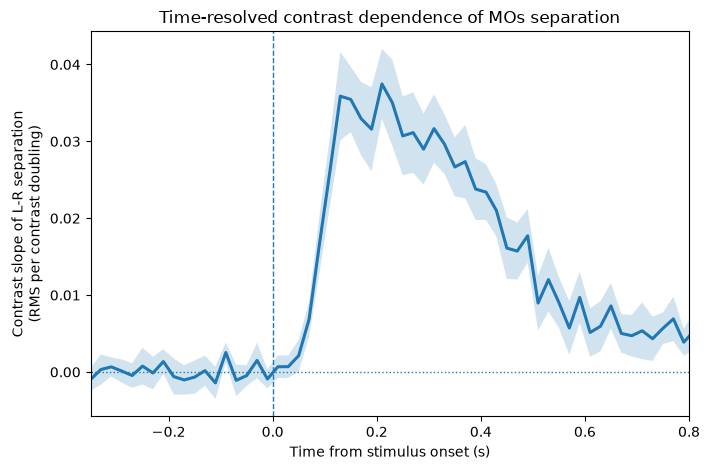

In [129]:
fig, ax = plt.subplots(
    figsize=(7.2, 4.8)
)


ax.plot(
    slope_group_df[
        "time_s"
    ],
    slope_group_df[
        "mean_slope"
    ],
    linewidth=2.2,
)


ax.fill_between(
    slope_group_df[
        "time_s"
    ],
    slope_group_df[
        "mean_slope"
    ]
    -
    slope_group_df[
        "sem_slope"
    ],

    slope_group_df[
        "mean_slope"
    ]
    +
    slope_group_df[
        "sem_slope"
    ],

    alpha=0.2,
)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
)


ax.axhline(
    0,
    linestyle=":",
    linewidth=1,
)


ax.set_xlim(
    -0.35,
    0.8,
)


ax.set_xlabel(
    "Time from stimulus onset (s)"
)


ax.set_ylabel(
    "Contrast slope of L-R separation\n(RMS per contrast doubling)"
)


ax.set_title(
    "Time-resolved contrast dependence of MOs separation"
)


plt.tight_layout()
plt.show()

In [130]:
from scipy.stats import t as student_t

# ============================================================
# 60E. Cluster-permutation configuration
# ============================================================

CLUSTER_N_PERMUTATIONS = 5000

# Candidate-bin threshold
CLUSTER_FORMING_ALPHA = 0.05

# Final cluster significance
CLUSTER_ALPHA = 0.05

CLUSTER_RANDOM_SEED = 20260812

In [131]:
# ============================================================
# 60F. Prepare subject × time slope matrix
# ============================================================

slope_analysis_df = (
    time_resolved_slope_df.loc[
        (
            time_resolved_slope_df[
                "time_s"
            ]
            >= ONSET_START_S
        )
        &
        (
            time_resolved_slope_df[
                "time_s"
            ]
            <= ONSET_END_S
        )
    ]
    .copy()
)
slope_matrix_df = (
    slope_analysis_df
    .pivot(
        index="subject",
        columns="time_s",
        values="contrast_slope",
    )
    .sort_index(
        axis=1
    )
)


slope_matrix = (
    slope_matrix_df
    .to_numpy(
        dtype=float
    )
)


cluster_time_s = (
    slope_matrix_df
    .columns
    .to_numpy(
        dtype=float
    )
)


print(
    "Slope matrix:",
    slope_matrix.shape
)

Slope matrix: (18, 40)


In [132]:
# ============================================================
# 60G. Compute one-sample t statistic across subjects
# ============================================================

def compute_group_t_stat(
    values,
):

    n = (
        values.shape[0]
    )


    mean_values = (
        values.mean(
            axis=0
        )
    )


    std_values = (
        values.std(
            axis=0,
            ddof=1,
        )
    )


    standard_error = (
        std_values
        /
        np.sqrt(
            n
        )
    )


    t_values = np.divide(
        mean_values,
        standard_error,
        out=np.zeros_like(
            mean_values
        ),
        where=(
            standard_error
            > 0
        ),
    )


    return t_values

In [133]:
# ============================================================
# 60H. Find contiguous positive clusters
# ============================================================

def find_positive_clusters(
    t_values,
    threshold,
):

    above_threshold = (
        t_values
        >
        threshold
    )


    clusters = []

    current_cluster = []


    for index, is_above in enumerate(
        above_threshold
    ):

        if is_above:

            current_cluster.append(
                index
            )

        else:

            if len(
                current_cluster
            ) > 0:

                clusters.append(
                    np.asarray(
                        current_cluster,
                        dtype=int,
                    )
                )

                current_cluster = []


    if len(
        current_cluster
    ) > 0:

        clusters.append(
            np.asarray(
                current_cluster,
                dtype=int,
            )
        )


    return clusters

In [134]:
# ============================================================
# 60I. Observed clusters
# ============================================================

n_subjects = (
    slope_matrix.shape[0]
)


degrees_of_freedom = (
    n_subjects
    -
    1
)


cluster_forming_threshold = (
    student_t.ppf(
        1.0
        -
        CLUSTER_FORMING_ALPHA,
        df=degrees_of_freedom,
    )
)


print(
    "Cluster-forming t threshold:",
    cluster_forming_threshold
)
observed_t = (
    compute_group_t_stat(
        slope_matrix
    )
)
observed_clusters = (
    find_positive_clusters(
        observed_t,
        cluster_forming_threshold,
    )
)
observed_cluster_masses = [
    float(
        observed_t[
            cluster
        ].sum()
    )
    for cluster
    in observed_clusters
]

Cluster-forming t threshold: 1.7396067260750727


In [135]:
# ============================================================
# 60J. Cluster-based sign-flip permutation
# ============================================================

rng = np.random.default_rng(
    CLUSTER_RANDOM_SEED
)


null_max_cluster_mass = np.zeros(
    CLUSTER_N_PERMUTATIONS,
    dtype=float,
)


for permutation_index in range(
    CLUSTER_N_PERMUTATIONS
):

    # --------------------------------------------------------
    # One sign per SUBJECT
    # Same sign across the complete timecourse
    # --------------------------------------------------------

    signs = rng.choice(
        [
            -1.0,
            1.0,
        ],
        size=(
            n_subjects,
            1,
        ),
    )


    permuted_slopes = (
        slope_matrix
        *
        signs
    )


    permuted_t = (
        compute_group_t_stat(
            permuted_slopes
        )
    )


    permuted_clusters = (
        find_positive_clusters(
            permuted_t,
            cluster_forming_threshold,
        )
    )


    if len(
        permuted_clusters
    ) == 0:

        null_max_cluster_mass[
            permutation_index
        ] = 0.0

    else:

        permutation_cluster_masses = [
            float(
                permuted_t[
                    cluster
                ].sum()
            )
            for cluster
            in permuted_clusters
        ]


        null_max_cluster_mass[
            permutation_index
        ] = max(
            permutation_cluster_masses
        )

In [136]:
# ============================================================
# 60K. Cluster-level permutation p-values
# ============================================================

cluster_result_rows = []


for cluster_index, (
    cluster,
    cluster_mass,
) in enumerate(
    zip(
        observed_clusters,
        observed_cluster_masses,
    ),
    start=1,
):


    cluster_p = (
        1
        +
        np.sum(
            null_max_cluster_mass
            >=
            cluster_mass
        )
    ) / (
        CLUSTER_N_PERMUTATIONS
        +
        1
    )


    first_center_s = float(
        cluster_time_s[
            cluster[0]
        ]
    )


    last_center_s = float(
        cluster_time_s[
            cluster[-1]
        ]
    )


    # Physical bin boundaries
    cluster_left_edge_s = (
        first_center_s
        -
        BIN_SIZE_S / 2
    )


    cluster_right_edge_s = (
        last_center_s
        +
        BIN_SIZE_S / 2
    )


    # Conservative timing:
    # the first 20-ms bin is fully observed
    # only at its right edge.
    conservative_start_s = (
        first_center_s
        +
        BIN_SIZE_S / 2
    )


    cluster_result_rows.append(
        {
            "cluster":
                cluster_index,

            "start_bin_center_s":
                first_center_s,

            "end_bin_center_s":
                last_center_s,

            "cluster_left_edge_s":
                cluster_left_edge_s,

            "cluster_right_edge_s":
                cluster_right_edge_s,

            "conservative_start_s":
                conservative_start_s,

            "n_bins":
                len(
                    cluster
                ),

            "cluster_mass":
                cluster_mass,

            "permutation_p":
                cluster_p,

            "significant":
                cluster_p
                <
                CLUSTER_ALPHA,
        }
    )

cluster_results_df = pd.DataFrame(
    cluster_result_rows
)


display(
    cluster_results_df
)

cluster_results_df.to_csv(
    TABLE_DIR
    /
    "time_resolved_contrast_slope_clusters.csv",
    index=False,
)

,cluster,start_bin_center_s,end_bin_center_s,cluster_left_edge_s,cluster_right_edge_s,conservative_start_s,n_bins,cluster_mass,permutation_p,significant
0,1,0.07,0.55,0.06,0.56,0.08,25,140.643686,0.000200,True
1,2,0.59,0.59,0.58,0.60,0.60,1,2.907147,0.180564,False
2,3,0.63,0.69,0.62,0.70,0.64,4,8.448623,0.079384,False
3,4,0.75,0.79,0.74,0.80,0.76,3,7.350105,0.088782,False


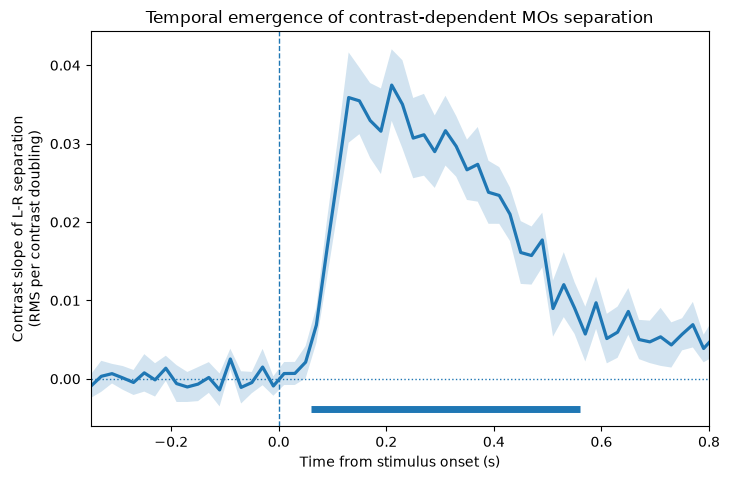

In [137]:
# ============================================================
# 60L. Final time-resolved timing figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.4, 4.9)
)


# ------------------------------------------------------------
# Group mean ± SEM
# ------------------------------------------------------------

ax.plot(
    slope_group_df[
        "time_s"
    ],
    slope_group_df[
        "mean_slope"
    ],
    linewidth=2.3,
)


ax.fill_between(
    slope_group_df[
        "time_s"
    ],

    slope_group_df[
        "mean_slope"
    ]
    -
    slope_group_df[
        "sem_slope"
    ],

    slope_group_df[
        "mean_slope"
    ]
    +
    slope_group_df[
        "sem_slope"
    ],

    alpha=0.2,
)


# ------------------------------------------------------------
# Reference lines
# ------------------------------------------------------------

ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
)


ax.axhline(
    0,
    linestyle=":",
    linewidth=1,
)


# ------------------------------------------------------------
# Significant clusters
# ------------------------------------------------------------

if len(
    cluster_results_df
) > 0:

    significant_clusters_df = (
        cluster_results_df.loc[
            cluster_results_df[
                "significant"
            ]
        ]
    )


    y_min, y_max = (
        ax.get_ylim()
    )


    significance_y = (
        y_min
        +
        0.04
        *
        (
            y_max
            -
            y_min
        )
    )


    for _, cluster_row in (
        significant_clusters_df.iterrows()
    ):

        ax.hlines(
            significance_y,

            xmin=
                cluster_row[
                    "cluster_left_edge_s"
                ],

            xmax=
                cluster_row[
                    "cluster_right_edge_s"
                ],

            linewidth=5,
        )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlim(
    -0.35,
    0.8,
)


ax.set_xlabel(
    "Time from stimulus onset (s)"
)


ax.set_ylabel(
    "Contrast slope of L-R separation\n"
    "(RMS per contrast doubling)"
)


ax.set_title(
    "Temporal emergence of contrast-dependent MOs separation"
)


plt.tight_layout()


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "05_time_resolved_contrast_slope_cluster_permutation.png",
    dpi=300,
    bbox_inches="tight",
)


fig.savefig(
    SUMMARY_FIGURE_DIR
    /
    "05_time_resolved_contrast_slope_cluster_permutation.pdf",
    bbox_inches="tight",
)


plt.show()